<a href="https://colab.research.google.com/github/Habibfipa/beginning-bioinformatics/blob/main/notebooks/Metagenomics_Gut_to_Soil_QIIME2_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Gut-to-soil microbiome analysis

**Name:** HABIB WOULEO FIPA  
**Student ID:** 1002335966  
**Date:** November 1, 2026
### Running the completed notebook

Run the setup cells and analytical cells in order in a Linux x86_64 Google Colab or Jupyter runtime. All 24 tutorial commands are supplied. The adapter runs them in the installed QIIME environment and retains tutorial filenames. It limits computational batch sizes and worker counts without changing the tutorial's biological settings.

Open the generated QZV files with [QIIME 2 View](https://view.qiime2.org/). Static summaries and the optional machine-learning results are included when generated. Download the results ZIP before the runtime ends. Official Zenodo input URLs and a GTDB 202.0 reference rebuild provide fallbacks if the tutorial download host is unavailable.

### Colab adjustments handled for you
The adapter prints the final command before running it. It limits DADA2 threads, taxonomy-training batch size, and taxonomy-classification workers/batches. It saves the classifier annotation to a separate file and uses that annotated copy downstream. Provenance paths are adjusted to this notebook's folder. All biological settings remain those in your pasted command. Reference artifacts and input reads are provided by download helpers so the exercise focuses on analytical commands.



## Provided setup A : Settings and file helpers

Keep the release fixed. The configuration records downloaded-file checksums and the installed environment. The release environment is pinned by its published specification; its URL is not a content-addressed lockfile. Downloads and generated results live on the Colab VM until you export them.

If you change an analysis parameter, rerun that cell and every downstream cell. The runner detects changed inputs/commands and recomputes outputs. The student tasks compute DADA2; the recovery section provides separately labeled reference plots if needed.


In [1]:
from pathlib import Path
import os, sys, json, shlex, shutil, subprocess, hashlib, time, urllib.request
import tarfile, zipfile, platform, html
import urllib.error

RELEASE = "2026.10"
DADA2_MODE = "compute"             # "compute" or "checkpoint"
REFERENCE_SOURCE = "tutorial-artifacts"  # or "rebuild" (download from GTDB)
THREADS = 2
TRAINING_CHUNK_SIZE = 200          # tutorial uses 2000; smaller lowers transient RAM
SAMPLING_DEPTH = 96                # shallow tutorial subset, not a research recommendation
RAREFACTIONS = 10
SEED = 42
assert DADA2_MODE in {"compute", "checkpoint"}
assert REFERENCE_SOURCE in {"tutorial-artifacts", "rebuild"}
assert platform.system() == "Linux" and platform.machine() in {"x86_64", "AMD64"}

ROOT = Path('/content/gut_to_soil_student')
WORK = ROOT / 'analysis'
LOGS = ROOT / 'logs'
for p in (ROOT, WORK, LOGS): p.mkdir(parents=True, exist_ok=True)
MM = ROOT / 'bin' / 'micromamba'
PREFIX = ROOT / ('qiime-' + RELEASE)
BASE = f'https://gut-to-soil-tutorial.readthedocs.io/en/{RELEASE}/data/gut-to-soil/'
ENV_URL = f'https://raw.githubusercontent.com/qiime2/distributions/refs/heads/dev/{RELEASE}/qiime2/released/rachis-qiime2-linux-64-conda.yml'
RUN_ENV = os.environ.copy()
# Prevent notebook-side Python settings from leaking into the QIIME process.
for key in ('PYTHONPATH', 'PYTHONHOME'): RUN_ENV.pop(key, None)
RUN_ENV.update(MAMBA_ROOT_PREFIX=str(ROOT / 'mamba'), PYTHONNOUSERSITE='1',
               MPLBACKEND='Agg', OMP_NUM_THREADS=str(THREADS),
               OPENBLAS_NUM_THREADS='1', MKL_NUM_THREADS='1')

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for b in iter(lambda: f.read(1024*1024), b''): h.update(b)
    return h.hexdigest()

def record(name, item):
    p = ROOT / name
    data = json.loads(p.read_text()) if p.exists() else []
    data.append(dict(time=time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime()), **item))
    p.write_text(json.dumps(data, indent=2))

def download(url, dest, *, refresh=False):
    dest = Path(dest); dest.parent.mkdir(parents=True, exist_ok=True)
    if dest.exists() and dest.stat().st_size and not refresh:
        return dest
    temp = dest.with_name(dest.name + '.part')
    for attempt in range(3):
        try:
            req = urllib.request.Request(url, headers={'User-Agent':'GutToSoilTeachingNotebook/1.0'})
            with urllib.request.urlopen(req, timeout=120) as response, temp.open('wb') as out:
                shutil.copyfileobj(response, out)
            if not temp.stat().st_size: raise ValueError('Empty download')
            if dest.suffix in {'.qza', '.qzv', '.zip'}:
                if not zipfile.is_zipfile(temp): raise ValueError('Expected ZIP/QIIME artifact; got another file type')
                with zipfile.ZipFile(temp) as z:
                    bad = z.testzip()
                    if bad: raise ValueError('Corrupt ZIP member: '+bad)
            elif dest.suffix in {'.tsv', '.yml'}:
                beginning = temp.read_text()[:200].lower()
                if '<html' in beginning or '<!doctype' in beginning:
                    raise ValueError('Received an HTML page instead of data')
            temp.replace(dest)
            record('downloads.json', dict(url=url, path=str(dest.relative_to(ROOT)),
                   bytes=dest.stat().st_size, sha256=sha256(dest)))
            print('Downloaded', dest.name, f'({dest.stat().st_size/1e6:.1f} MB)')
            return dest
        except Exception:
            temp.unlink(missing_ok=True)
            if attempt == 2: raise
            time.sleep(2)

ORIGINAL_STUDY_INPUTS = {
    'sample-metadata.tsv': 'https://zenodo.org/records/15390940/files/gut-to-soil-tutorial-sample-metadata.tsv?download=1',
    'demux.qza': 'https://zenodo.org/records/15390940/files/gut-to-soil-tutorial-nano2-demux-10p.qza?download=1',
}

def fetch(name, dest=None):
    target = WORK / (dest or name)
    try:
        return download(BASE + name, target)
    except urllib.error.HTTPError as error:
        if error.code not in {403, 404, 429, 502, 503} or name not in ORIGINAL_STUDY_INPUTS:
            raise
        print('Tutorial host unavailable; using the original study input:', name)
        return download(ORIGINAL_STUDY_INPUTS[name], target)

def run(argv, log_name='command', cwd=None):
    argv = [str(a) for a in argv]
    print('$', shlex.join(argv), flush=True)
    log = LOGS / (log_name + '.log')
    started = time.monotonic()
    with log.open('w') as f:
        p = subprocess.Popen(argv, cwd=cwd or WORK, env=RUN_ENV,
                             stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                             text=True, bufsize=1)
        try:
            for line in p.stdout:
                print(line, end='', flush=True); f.write(line); f.flush()
            rc = p.wait()
        except BaseException:
            p.terminate()
            try: p.wait(timeout=10)
            except subprocess.TimeoutExpired: p.kill(); p.wait()
            raise
    record('runs.json', dict(command=argv, returncode=rc,
           seconds=round(time.monotonic()-started, 2), log=str(log.relative_to(ROOT))))
    if rc:
        raise RuntimeError(f'Command failed (exit {rc}). Read {log}. No checkpoint was substituted.')

# Some hosted workspaces expose /proc/self but not namespace-local numeric PIDs.
# Use the same process start time via /proc/self for QIIME cache naming and CPU-affinity discovery.
COMPAT_CLI = ROOT / 'qiime_namespace_compat.py'
COMPAT_CLI.write_text(r"""from pathlib import Path
import os, sys
import psutil
import rachis.core.cache as cache
original_pool_name = cache.Pool._get_process_pool_name

def namespace_pool_name(self):
    try:
        return original_pool_name(self)
    except psutil.NoSuchProcess:
        # Field 22 is start time in clock ticks since boot. Fields after the
        # closing ')' begin at field 3, so field 22 has index 19 here.
        fields = Path('/proc/self/stat').read_text().rsplit(')', 1)[1].split()
        created = psutil.boot_time() + int(fields[19]) / os.sysconf('SC_CLK_TCK')
        return f'{os.getpid()}-{created}@{cache._get_user()}'

cache.Pool._get_process_pool_name = namespace_pool_name
# Read the current process's actual CPU affinity directly when numeric
# PID lookups are unavailable in this hosted process namespace.
if not (Path('/proc') / str(os.getpid())).exists():
    import types
    import q2_diversity_lib._util as diversity_util
    diversity_util.psutil = types.SimpleNamespace(
        cpu_count=psutil.cpu_count,
        Process=lambda: types.SimpleNamespace(
            cpu_affinity=lambda: sorted(os.sched_getaffinity(0))))
from qiime2.__main__ import qiime
sys.argv[0] = 'qiime'
sys.exit(qiime())
""")
USE_NAMESPACE_COMPAT = not (Path('/proc') / str(os.getpid())).exists()
def qcmd(args):
    launcher = ['python', COMPAT_CLI] if USE_NAMESPACE_COMPAT else ['qiime']
    return [MM, 'run', '-p', PREFIX, *launcher, *args]
if USE_NAMESPACE_COMPAT:
    print('Using namespace-compatible cache naming; analysis parameters are unchanged.')


mem = dict(line.split(':',1) for line in Path('/proc/meminfo').read_text().splitlines())
print('Available RAM:', round(int(mem['MemAvailable'].split()[0])/1024**2,1), 'GiB')
print('Free disk:', round(shutil.disk_usage(ROOT).free/1024**3,1), 'GiB')
print('Notebook Python:', sys.executable, '(will remain unchanged)')


Available RAM: 11.7 GiB
Free disk: 107.6 GiB
Notebook Python: /usr/bin/python3 (will remain unchanged)


## Provided setup B : Installation

This uses the official release environment with micromamba as its Conda-compatible installer. It does not replace Colab's Python. Installation may be lengthy; inspect the live output. If it fails, keep the installation log rather than adding arbitrary `pip install` fixes. The initial free-space check is a conservative classroom guard, not an official minimum.


In [2]:
if not MM.exists():
    package = download('https://micro.mamba.pm/api/micromamba/linux-64/latest', ROOT/'micromamba.tar.bz2')
    with tarfile.open(package) as tar:
        member = tar.getmember('bin/micromamba')
        MM.parent.mkdir(exist_ok=True)
        with tar.extractfile(member) as src, MM.open('wb') as dst:
            shutil.copyfileobj(src, dst)
    MM.chmod(0o755)
run([MM, '--version'], 'micromamba-version')
env_file = download(ENV_URL, ROOT/f'qiime-{RELEASE}.yml')
ready = PREFIX / '.notebook-install-complete'
if not ready.exists():
    if shutil.disk_usage(ROOT).free < 20*1024**3:
        raise RuntimeError('Less than 20 GiB free. Start a fresh runtime or free space before installation.')
    run([MM, 'create', '-y', '-p', PREFIX, '-f', env_file], 'installation')
    run(qcmd(['info']), 'qiime-info')
    ready.write_text(sha256(env_file))
else:
    assert ready.read_text() == sha256(env_file), 'Environment specification changed; use a fresh runtime.'
    run(qcmd(['info']), 'qiime-info')
run([MM, 'list', '-p', PREFIX, '--explicit'], 'environment-explicit')
print('Installation passed qiime info. Next: test the actual tutorial actions.')


Downloaded micromamba.tar.bz2 (7.3 MB)
$ /content/gut_to_soil_student/bin/micromamba --version
2.10.0
Downloaded qiime-2026.10.yml (0.0 MB)
$ /content/gut_to_soil_student/bin/micromamba create -y -p /content/gut_to_soil_student/qiime-2026.10 -f /content/gut_to_soil_student/qiime-2026.10.yml
⚠ Shard Index for https://packages.qiime2.org/qiime2/2026.10/qiime2/released/linux-64 not available, falling back to flat repodata
Using Flat Repodata for https://packages.qiime2.org/qiime2/2026.10/qiime2/released...           ✔ Starting
Using Flat Repodata for https://packages.qiime2.org/qiime2/2026.10/qiime2/released...     ✔ Done (0.0 sec)
⚠ Shard Index for https://packages.qiime2.org/qiime2/2026.10/qiime2/released/noarch not available, falling back to flat repodata
Using Flat Repodata for https://packages.qiime2.org/qiime2/2026.10/qiime2/released...           ✔ Starting
Using Flat Repodata for https://packages.qiime2.org/qiime2/2026.10/qiime2/released...     ✔ Done (0.0 sec)
Fetch Shard Index fo

## Provided setup C : Compatibility checks and runner

This checks release-specific command flags before the analysis starts. A successful preflight verifies the CLI, not the analysis itself. Each step writes a success record only after all expected outputs exist. Changed input bytes or changed commands invalidate cached results. Partial outputs are regenerated on retry.


In [3]:
checks = {
 ('dada2','denoise-paired'): ['--o-base-transition-stats','--p-n-threads'],
 ('feature-table','summarize'): ['--o-summary','--o-sample-frequencies','--m-metadata-file'],
 ('feature-table','tabulate-seqs'): ['--i-taxonomy'],
 ('feature-classifier','fit-classifier-naive-bayes'): ['--p-classify--chunk-size'],
 ('feature-classifier','classify-sklearn'): ['--p-reads-per-batch','--p-n-jobs'],
 ('boots','kmer-diversity'): ['--p-n','--p-no-replacement'],
 ('composition','ancombc2'): ['--p-fixed-effects-formula','--o-ancombc2-output'],
 ('composition','da-barplot'): ['--i-data'],
 ('rescript','get-gtdb-data'): ['--p-db-type'],
 ('tools','annotation-create'): ['--annotation-type'],
 ('tools','replay-provenance'): ['--in-fp','--out-fp'],
}
problems=[]
for action, flags in checks.items():
    p = subprocess.run([str(x) for x in qcmd([*action,'--help'])], env=RUN_ENV,
                       text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    (LOGS/('help-'+'-'.join(action)+'.log')).write_text(p.stdout)
    missing=[f for f in flags if f not in p.stdout]
    if p.returncode or missing: problems.append((' '.join(action),missing,p.returncode))
if problems: raise RuntimeError(f'Release/API mismatch: {problems}. See help logs; do not mix tutorial releases.')
print('All tutorial API checks passed.')

def digest_path(p):
    p=Path(p)
    if p.is_file(): return sha256(p)
    if p.is_dir():
        return hashlib.sha256(json.dumps([(str(f.relative_to(p)),sha256(f))
             for f in sorted(p.rglob('*')) if f.is_file()]).encode()).hexdigest()
    return None

def step(name, command, outputs):
    argv=shlex.split(command)
    assert argv[0]=='qiime'
    paths=[WORK/o for o in outputs]
    for p in paths:
        assert p.resolve().is_relative_to(WORK.resolve()) and p.resolve()!=WORK.resolve()
    inputs={}
    for token in argv[1:]:
        candidate=WORK/token
        # Named collection arguments use label:path.
        if not candidate.exists() and ':' in token: candidate=WORK/token.split(':',1)[1]
        if candidate.exists() and candidate not in paths:
            inputs[str(candidate.relative_to(WORK))]=digest_path(candidate)
    signature=hashlib.sha256(json.dumps([command,inputs,RELEASE],sort_keys=True).encode()).hexdigest()
    marker=LOGS/('step-'+hashlib.sha256(name.encode()).hexdigest()[:12]+'.json')
    old=json.loads(marker.read_text()) if marker.exists() else {}
    observed={o:digest_path(WORK/o) for o in outputs}
    if old.get('signature')==signature and all(observed.values()) and old.get('outputs')==observed:
        print('Already completed:',name); return
    marker.unlink(missing_ok=True)
    for p in paths:
        if p.is_dir(): shutil.rmtree(p)
        elif p.exists(): p.unlink()
    run(qcmd(argv[1:]), 'step-'+hashlib.sha256(name.encode()).hexdigest()[:12])
    observed={o:digest_path(WORK/o) for o in outputs}
    if not all(observed.values()): raise RuntimeError(f'Missing outputs for {name}: {observed}')
    marker.write_text(json.dumps(dict(name=name,signature=signature,outputs=observed),indent=2))

def view_outputs():
    from IPython.display import display, HTML
    import ipywidgets as w
    paths=sorted(WORK.rglob('*.qzv'))
    if not paths: print('No visualizations yet.'); return
    choices=w.Dropdown(options=[(str(p.relative_to(WORK)),str(p)) for p in paths],
                       description='Result:',layout=w.Layout(width='90%'))
    button=w.Button(description='Download selected .qzv')
    def selected(_):
        try:
            from google.colab import files
            files.download(choices.value)
        except ImportError:
            from IPython.display import FileLink
            display(FileLink(choices.value))
    button.on_click(selected)
    display(HTML('<p>Download a visualization, then open it at <a href="https://view.qiime2.org/" target="_blank">QIIME 2 View</a>. Inspect its provenance as well as its plots.</p>'))
    display(choices,button)


All tutorial API checks passed.


## Provided setup D : Paste-in adapter
Run once. This accepts a **single QIIME command** per task. It recognizes the requested outputs, applies the Colab adjustments listed above, and passes the command to the tested runner. It does not fill in missing commands or invent results.


In [4]:
def tutorial_step(task, command):
    if 'PASTE_TUTORIAL_COMMAND_HERE' in command or not command.strip():
        raise ValueError(f'{task}: paste the indicated tutorial command between the triple quotes first.')
    command = command.replace('\\\n', '')
    args = shlex.split(command)
    if not args or args[0] != 'qiime' or args.count('qiime') != 1:
        raise ValueError('Paste exactly one command beginning with qiime, without !, $, cd, or code fences.')
    if any(x in args for x in [';', '&&', '|']):
        raise ValueError('Paste one command only, without shell operators.')
    def option(flag, value):
        if flag in args:
            j=args.index(flag)
            if j+1==len(args): raise ValueError(f'Missing value after {flag}')
            args[j+1]=str(value)
        else: args.extend([flag,str(value)])
    action=tuple(args[1:3])
    if action == ('dada2','denoise-paired'): option('--p-n-threads', THREADS)
    if action == ('feature-classifier','fit-classifier-naive-bayes'):
        option('--p-classify--chunk-size',TRAINING_CHUNK_SIZE)
    if action == ('feature-classifier','classify-sklearn'):
        option('--p-n-jobs',1); option('--p-reads-per-batch',100)
        j=args.index('--i-classifier')+1
        if args[j]=='suboptimal-16S-rRNA-classifier.qza': args[j]='teaching-classifier.qza'
    if action == ('tools','annotation-create'):
        option('--output-path','teaching-classifier.qza')
    if action == ('tools','replay-provenance'):
        option('--in-fp',WORK); option('--out-fp',ROOT/'g2s-replayed.bash')
        run(qcmd(args[1:]),'student-provenance')
        return
    outputs=[]
    for i,arg in enumerate(args):
        if arg.startswith('--o-') or arg in {'--output-dir','--output-path'}:
            if i+1==len(args): raise ValueError(f'Missing filename after {arg}')
            outputs.append(args[i+1])
    if not outputs: raise ValueError('No output flags found. Paste the entire command, including output options.')
    print('Command to run:',shlex.join(args))
    step(task,shlex.join(args),outputs)


## Worked example : Metadata
The tutorial's **Reviewing sample metadata and running a QIIME 2 command** section creates a metadata visualization. Notice that `--m-input-file` identifies metadata and `--o-visualization` names an output. Everything between the triple quotes is a normal tutorial command.

The downloads below are provided. Metadata describes each sample; `demux.qza` contains the already imported paired-end reads.


In [5]:
fetch('sample-metadata.tsv')
fetch('demux.qza')


Downloaded sample-metadata.tsv (0.4 MB)
Downloaded demux.qza (13.2 MB)


PosixPath('/content/gut_to_soil_student/analysis/demux.qza')

In [6]:
tutorial_step("Worked example: metadata", r"""
qiime metadata tabulate \
  --m-input-file sample-metadata.tsv \
  --o-visualization sample-metadata.qzv
""")
view_outputs()


Command to run: qiime metadata tabulate --m-input-file sample-metadata.tsv --o-visualization sample-metadata.qzv
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime metadata tabulate --m-input-file sample-metadata.tsv --o-visualization sample-metadata.qzv
Saved Visualization to: sample-metadata.qzv


Dropdown(description='Result:', layout=Layout(width='90%'), options=(('sample-metadata.qzv', '/content/gut_to_…

Button(description='Download selected .qzv', style=ButtonStyle())

## 4. Get the tutorial reads and metadata

**Find in the tutorial:** Summarize demultiplexed sequences.

Before executing, identify what each input contains and predict what this step will produce.


### Task 1: Read quality

Find the command beginning **`qiime demux summarize`**.

**Expected output(s):** `demux.qzv`.


In [7]:
tutorial_step('Task 1: Read quality', r"""
qiime demux summarize \
  --i-data demux.qza \
  --o-visualization demux.qzv
""")


Command to run: qiime demux summarize --i-data demux.qza --o-visualization demux.qzv
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime demux summarize --i-data demux.qza --o-visualization demux.qzv
Saved Visualization to: demux.qzv


In [8]:
view_outputs()


Dropdown(description='Result:', layout=Layout(width='90%'), options=(('demux.qzv', '/content/gut_to_soil_stude…

Button(description='Download selected .qzv', style=ButtonStyle())

**Pause and explain:** What are the observations in the metadata? Which column describes sample environment? Record one observation from the read-quality plot.

**Your response:**

Each metadata row is one collected sample, keyed by sample-id. SampleType describes its environment, while Bucket, Composting Time Point, and Compost pH describe its source and collection conditions. In the computed quality summary, median quality at base 250 is Q37 in both directions. The reverse-read median falls to Q14 at base 251. This supports retaining the initial bases and truncating both directions at 250, as in the tutorial. Metadata can cover more samples than the 104 identifiers represented in this tutorial's sequencing subset.


## 5. DADA2: reads → ASVs and counts

**Find in the tutorial:** Sequence quality control and feature table construction.

Before executing, identify what each input contains and predict what this step will produce.


### Task 2: DADA2

Find the command beginning **`qiime dada2 denoise-paired`**.

**Expected output(s):** `asv-seqs.qza`, `asv-table.qza`, `denoising-stats.qza`, `base-transition-stats.qza`.


In [9]:
tutorial_step('Task 2: DADA2', r"""
qiime dada2 denoise-paired \
  --i-demultiplexed-seqs demux.qza \
  --p-trim-left-f 0 \
  --p-trunc-len-f 250 \
  --p-trim-left-r 0 \
  --p-trunc-len-r 250 \
  --o-representative-sequences asv-seqs.qza \
  --o-table asv-table.qza \
  --o-denoising-stats denoising-stats.qza \
  --o-base-transition-stats base-transition-stats.qza
""")


Command to run: qiime dada2 denoise-paired --i-demultiplexed-seqs demux.qza --p-trim-left-f 0 --p-trunc-len-f 250 --p-trim-left-r 0 --p-trunc-len-r 250 --o-representative-sequences asv-seqs.qza --o-table asv-table.qza --o-denoising-stats denoising-stats.qza --o-base-transition-stats base-transition-stats.qza --p-n-threads 2
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime dada2 denoise-paired --i-demultiplexed-seqs demux.qza --p-trim-left-f 0 --p-trunc-len-f 250 --p-trim-left-r 0 --p-trunc-len-r 250 --o-representative-sequences asv-seqs.qza --o-table asv-table.qza --o-denoising-stats denoising-stats.qza --o-base-transition-stats base-transition-stats.qza --p-n-threads 2
Saved FeatureTable[Frequency] to: asv-table.qza
Saved FeatureData[Sequence] to: asv-seqs.qza
Saved SampleData[DADA2Stats] to: denoising-stats.qza
Saved DADA2BaseTransitionStats to: base-transition-stats.qza


### Task 3: DADA2 statistics

Find the command beginning **`qiime metadata tabulate`**.

**Expected output(s):** `denoising-stats.qzv`.


In [10]:
tutorial_step('Task 3: DADA2 statistics', r"""
qiime metadata tabulate \
  --m-input-file denoising-stats.qza \
  --o-visualization denoising-stats.qzv
""")


Command to run: qiime metadata tabulate --m-input-file denoising-stats.qza --o-visualization denoising-stats.qzv
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime metadata tabulate --m-input-file denoising-stats.qza --o-visualization denoising-stats.qzv
Saved Visualization to: denoising-stats.qzv


### Task 4: Combined metadata

Find the command beginning **`qiime metadata tabulate`**.

**Expected output(s):** `sample-metadata-w-dada2-stats.qzv`.


In [11]:
tutorial_step('Task 4: Combined metadata', r"""
qiime metadata tabulate \
  --m-input-file sample-metadata.tsv denoising-stats.qza \
  --o-visualization sample-metadata-w-dada2-stats.qzv
""")


Command to run: qiime metadata tabulate --m-input-file sample-metadata.tsv denoising-stats.qza --o-visualization sample-metadata-w-dada2-stats.qzv
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime metadata tabulate --m-input-file sample-metadata.tsv denoising-stats.qza --o-visualization sample-metadata-w-dada2-stats.qzv
Saved Visualization to: sample-metadata-w-dada2-stats.qzv


In [12]:
view_outputs()


Dropdown(description='Result:', layout=Layout(width='90%'), options=(('demux.qzv', '/content/gut_to_soil_stude…

Button(description='Download selected .qzv', style=ButtonStyle())

**Pause and explain:** Which processing stage lost the most reads for one sample you chose? Explain the distinction between an ASV, a read, and a species.

**Your response:**

For sample 21f2e6d0, the counts are 669 input, 547 filtered, 455 denoised, 423 merged, and 423 non-chimeric reads. Quality filtering loses the most reads: 122, compared with 92 during denoising, 32 during merging, and 0 during chimera removal. A read is one sequencing observation. An ASV is an inferred amplicon sequence after error correction, while a species is a biological taxonomic category. Several species can share a short 16S sequence, and one genome can contain several 16S variants, so an ASV is not automatically one species.


## 6. Summarize the count table

**Find in the tutorial:** Feature table and feature data summaries.

Before executing, identify what each input contains and predict what this step will produce.


### Task 5: 6. Summarize the count table

Find the command beginning **`qiime feature-table summarize`**.

**Expected output(s):** `asv-table.qzv`, `sample-frequencies.qza`, `asv-frequencies.qza`.


In [13]:
tutorial_step('Task 5: 6. Summarize the count table', r"""
qiime feature-table summarize \
  --i-table asv-table.qza \
  --m-metadata-file sample-metadata.tsv \
  --o-summary asv-table.qzv \
  --o-sample-frequencies sample-frequencies.qza \
  --o-feature-frequencies asv-frequencies.qza
""")


Command to run: qiime feature-table summarize --i-table asv-table.qza --m-metadata-file sample-metadata.tsv --o-summary asv-table.qzv --o-sample-frequencies sample-frequencies.qza --o-feature-frequencies asv-frequencies.qza
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime feature-table summarize --i-table asv-table.qza --m-metadata-file sample-metadata.tsv --o-summary asv-table.qzv --o-sample-frequencies sample-frequencies.qza --o-feature-frequencies asv-frequencies.qza
Saved ImmutableMetadata to: asv-frequencies.qza
Saved ImmutableMetadata to: sample-frequencies.qza
Saved Visualization to: asv-table.qzv


### Task 6: ASV sequences

Find the command beginning **`qiime feature-table tabulate-seqs`**.

**Expected output(s):** `asv-seqs.qzv`.


In [14]:
tutorial_step('Task 6: ASV sequences', r"""
qiime feature-table tabulate-seqs \
  --i-data asv-seqs.qza \
  --m-metadata-file asv-frequencies.qza \
  --o-visualization asv-seqs.qzv
""")


Command to run: qiime feature-table tabulate-seqs --i-data asv-seqs.qza --m-metadata-file asv-frequencies.qza --o-visualization asv-seqs.qzv
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime feature-table tabulate-seqs --i-data asv-seqs.qza --m-metadata-file asv-frequencies.qza --o-visualization asv-seqs.qzv
Saved Visualization to: asv-seqs.qzv


In [15]:
view_outputs()


Dropdown(description='Result:', layout=Layout(width='90%'), options=(('asv-seqs.qzv', '/content/gut_to_soil_st…

Button(description='Download selected .qzv', style=ButtonStyle())

**Pause and explain:** How many samples and ASVs remain? Find the most frequent ASV and record a sequence-based observation about it.

**Your response:**

The DADA2 table has 104 sample columns, 103 of them nonempty, and 1,069 ASVs representing 39,949 retained reads. The most frequent ASV is c6c3ab4e828fb40d6e05967b7aac9338, with 1,334 reads across 23 samples. Its merged sequence is 253 nucleotides long and begins TACGTAGGGGGCAAGCGTTATCCGGATTTACTGGGTGTAA. The sequence is 53.4% G+C. Its V4 sequence supports a Blautia-associated assignment, but matching short sequences cannot resolve one species confidently.


## 7. Filter rare features

**Find in the tutorial:** Filtering features from a feature table.

Before executing, identify what each input contains and predict what this step will produce.


### Task 7: 7. Filter rare features

Find the command beginning **`qiime feature-table filter-features`**.

**Expected output(s):** `asv-table-ms2.qza`.


In [16]:
tutorial_step('Task 7: 7. Filter rare features', r"""
qiime feature-table filter-features \
  --i-table asv-table.qza \
  --p-min-samples 2 \
  --o-filtered-table asv-table-ms2.qza
""")

Command to run: qiime feature-table filter-features --i-table asv-table.qza --p-min-samples 2 --o-filtered-table asv-table-ms2.qza
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime feature-table filter-features --i-table asv-table.qza --p-min-samples 2 --o-filtered-table asv-table-ms2.qza
Saved FeatureTable[Frequency] to: asv-table-ms2.qza


### Task 8: Filter sequences

Find the command beginning **`qiime feature-table filter-seqs`**.

**Expected output(s):** `asv-seqs-ms2.qza`.


In [17]:
tutorial_step('Task 8: Filter sequences', r"""
qiime feature-table filter-seqs \
  --i-data asv-seqs.qza \
  --i-table asv-table-ms2.qza \
  --o-filtered-data asv-seqs-ms2.qza
""")


Command to run: qiime feature-table filter-seqs --i-data asv-seqs.qza --i-table asv-table-ms2.qza --o-filtered-data asv-seqs-ms2.qza
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime feature-table filter-seqs --i-data asv-seqs.qza --i-table asv-table-ms2.qza --o-filtered-data asv-seqs-ms2.qza
Saved FeatureData[Sequence] to: asv-seqs-ms2.qza


### Task 9: Filtered table summary

Find the command beginning **`qiime feature-table summarize`**.

**Expected output(s):** `asv-table-ms2.qzv`, `sample-frequencies-ms2.qza`, `asv-frequencies-ms2.qza`.


In [18]:
tutorial_step('Task 9: Filtered table summary', r"""
qiime feature-table summarize \
  --i-table asv-table-ms2.qza \
  --m-metadata-file sample-metadata.tsv \
  --o-summary asv-table-ms2.qzv \
  --o-sample-frequencies sample-frequencies-ms2.qza \
  --o-feature-frequencies asv-frequencies-ms2.qza
""")


Command to run: qiime feature-table summarize --i-table asv-table-ms2.qza --m-metadata-file sample-metadata.tsv --o-summary asv-table-ms2.qzv --o-sample-frequencies sample-frequencies-ms2.qza --o-feature-frequencies asv-frequencies-ms2.qza
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime feature-table summarize --i-table asv-table-ms2.qza --m-metadata-file sample-metadata.tsv --o-summary asv-table-ms2.qzv --o-sample-frequencies sample-frequencies-ms2.qza --o-feature-frequencies asv-frequencies-ms2.qza
Saved ImmutableMetadata to: asv-frequencies-ms2.qza
Saved ImmutableMetadata to: sample-frequencies-ms2.qza
Saved Visualization to: asv-table-ms2.qzv


In [19]:
view_outputs()


Dropdown(description='Result:', layout=Layout(width='90%'), options=(('asv-seqs.qzv', '/content/gut_to_soil_st…

Button(description='Download selected .qzv', style=ButtonStyle())

**Pause and explain:** How many ASVs were removed? Explain why excluding single-sample features might change an estimate of richness.

**Your response:**

The minimum-two-samples filter removes 734 of 1,069 ASVs, leaving 335 ASVs and 99 nonempty samples. Total frequency decreases from 39,949 to 29,978, a loss of 9,971 represented reads. A removed feature occurs in only one sample, but may still have many reads. Removing these features lowers observed richness in the affected samples and can remove genuine rare or sample-specific organisms. It reduces computation and potentially some noise, so richness estimates must be interpreted conditional on this filter.


## 8. Reference sequences and taxonomy labels

**Find in the tutorial:** Taxonomic annotation → Training a taxonomic classifier.

Before executing, identify what each input contains and predict what this step will produce.


**Reference inputs:** Use the release-matched GTDB 202.0 sequence and taxonomy artifacts. If the tutorial host rejects downloads, the next cell rebuilds these inputs with the tutorial's RESCRIPt command using the same database version and SpeciesReps selection. The downstream classifier is trained in this notebook.


In [20]:
# Prefer release-matched published references. Rebuild the same GTDB 202.0
# inputs if that download host is unavailable.
try:
    fetch('reference-sequences.qza')
    fetch('reference-taxonomy.qza')
except urllib.error.HTTPError as error:
    if error.code not in {403, 404, 429, 502, 503}:
        raise
    print('Rebuilding reference inputs from GTDB 202.0 SpeciesReps.')
    reference_outputs = [WORK/'reference-sequences.qza', WORK/'reference-taxonomy.qza']
    if not all(p.exists() and p.stat().st_size for p in reference_outputs):
        for p in reference_outputs:
            p.unlink(missing_ok=True)
        run(qcmd(['rescript', 'get-gtdb-data',
                  '--p-version', '202.0', '--p-db-type', 'SpeciesReps',
                  '--p-db-url', 'australia',
                  '--o-gtdb-sequences', 'reference-sequences.qza',
                  '--o-gtdb-taxonomy', 'reference-taxonomy.qza']),
            'reference-gtdb-rebuild')
    record('reference-source.json', dict(source='GTDB rebuild', version='202.0',
           db_type='SpeciesReps',
           sha256={p.name:sha256(p) for p in reference_outputs}))


Downloaded reference-sequences.qza (11.5 MB)
Downloaded reference-taxonomy.qza (0.8 MB)


### Task 10: Reference summary

Find the command beginning **`qiime feature-table tabulate-seqs`**.

**Expected output(s):** `reference-taxonomy.qzv`.


In [21]:
tutorial_step('Task 10: Reference summary', r"""
qiime feature-table tabulate-seqs \
  --i-data reference-sequences.qza \
  --i-taxonomy GTDB_r202_SpeciesReps:reference-taxonomy.qza \
  --p-merge-method intersect \
  --o-visualization reference-taxonomy.qzv
""")


Command to run: qiime feature-table tabulate-seqs --i-data reference-sequences.qza --i-taxonomy GTDB_r202_SpeciesReps:reference-taxonomy.qza --p-merge-method intersect --o-visualization reference-taxonomy.qzv
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime feature-table tabulate-seqs --i-data reference-sequences.qza --i-taxonomy GTDB_r202_SpeciesReps:reference-taxonomy.qza --p-merge-method intersect --o-visualization reference-taxonomy.qzv
Saved Visualization to: reference-taxonomy.qzv


In [22]:
view_outputs()


Dropdown(description='Result:', layout=Layout(width='90%'), options=(('asv-seqs.qzv', '/content/gut_to_soil_st…

Button(description='Download selected .qzv', style=ButtonStyle())

**Pause and explain:** What are the training examples and their labels for taxonomy classification? How does the reference set limit the predictions?

**Your response:**

The training examples are GTDB 202.0 reference 16S sequences, and their labels are the corresponding taxonomic lineages from domain through the deepest available rank. The classifier learns associations between sequence k-mers and those lineages. It cannot confidently identify organisms or ranks that the reference set does not adequately represent. The older database, incomplete annotations, and the limited information in a short V4 amplicon all restrict prediction, which is why a high-confidence genus assignment can be more defensible than a species label.


## 9. Train a naïve Bayes taxonomy classifier

**Find in the tutorial:** Taxonomic annotation → Training a taxonomic classifier / Annotating an Artifact or Visualization.

Before executing, identify what each input contains and predict what this step will produce.


### Task 11: Train taxonomy classifier

Find the command beginning **`qiime feature-classifier fit-classifier-naive-bayes`**.

**Expected output(s):** `suboptimal-16S-rRNA-classifier.qza`.


In [23]:
tutorial_step('Task 11: Train taxonomy classifier', r"""
qiime feature-classifier fit-classifier-naive-bayes \
  --i-reference-reads reference-sequences.qza \
  --i-reference-taxonomy reference-taxonomy.qza \
  --p-feat-ext--n-features 2048 \
  --p-classify--chunk-size 2000 \
  --o-classifier suboptimal-16S-rRNA-classifier.qza
""")


Command to run: qiime feature-classifier fit-classifier-naive-bayes --i-reference-reads reference-sequences.qza --i-reference-taxonomy reference-taxonomy.qza --p-feat-ext--n-features 2048 --p-classify--chunk-size 200 --o-classifier suboptimal-16S-rRNA-classifier.qza
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime feature-classifier fit-classifier-naive-bayes --i-reference-reads reference-sequences.qza --i-reference-taxonomy reference-taxonomy.qza --p-feat-ext--n-features 2048 --p-classify--chunk-size 200 --o-classifier suboptimal-16S-rRNA-classifier.qza
Saved TaxonomicClassifier to: suboptimal-16S-rRNA-classifier.qza


### Task 12: Annotate classifier

Find the command beginning **`qiime tools annotation-create`**.

**Expected output(s):** `teaching-classifier.qza`.


The complete tutorial annotation command is supplied below. The adapter writes the annotated result to teaching-classifier.qza and uses that file for taxonomy classification. The unannotated classifier remains available separately.


In [24]:
tutorial_step('Task 12: Annotate classifier', r"""
qiime tools annotation-create \
  --input-path suboptimal-16S-rRNA-classifier.qza \
  --annotation-type Note \
  --name 'suboptimal-classifier-justification' \
  --text 'This classifier was trained with non-default parameters for demonstration purposes. It should not be used in real-world analysis.' \
  --output-path suboptimal-16S-rRNA-classifier.qza
""")


Command to run: qiime tools annotation-create --input-path suboptimal-16S-rRNA-classifier.qza --annotation-type Note --name suboptimal-classifier-justification --text 'This classifier was trained with non-default parameters for demonstration purposes. It should not be used in real-world analysis.' --output-path teaching-classifier.qza
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime tools annotation-create --input-path suboptimal-16S-rRNA-classifier.qza --annotation-type Note --name suboptimal-classifier-justification --text 'This classifier was trained with non-default parameters for demonstration purposes. It should not be used in real-world analysis.' --output-path teaching-classifier.qza
Added Note "suboptimal-classifier-justification" to teaching-classifier.qza


In [25]:
view_outputs()


Dropdown(description='Result:', layout=Layout(width='90%'), options=(('asv-seqs.qzv', '/content/gut_to_soil_st…

Button(description='Download selected .qzv', style=ButtonStyle())

**Pause and explain:** What do k-mer features encode? Explain why changing chunk size is different from changing the number of feature buckets.

**Your response:**

A k-mer is a short contiguous DNA word. The model represents sequences by the occurrence of those words, so the features capture local sequence patterns associated with reference taxa. The number of feature buckets, 2048 here, controls the hashed feature representation. Fewer buckets increase collisions between distinct k-mers and can lose information. Chunk size controls how many training examples are processed together, mainly affecting temporary memory use and runtime. The Colab adapter lowers chunk size from 2000 to 200 while retaining 2048 feature buckets.


## 10. Assign taxonomy

**Find in the tutorial:** Apply our taxonomy classifier.

Before executing, identify what each input contains and predict what this step will produce.


### Task 13: 10. Assign taxonomy

Find the command beginning **`qiime feature-classifier classify-sklearn`**.

**Expected output(s):** `taxonomy.qza`.


In [26]:
tutorial_step('Task 13: 10. Assign taxonomy', r"""
qiime feature-classifier classify-sklearn \
  --i-classifier suboptimal-16S-rRNA-classifier.qza \
  --i-reads asv-seqs-ms2.qza \
  --o-classification taxonomy.qza
""")


Command to run: qiime feature-classifier classify-sklearn --i-classifier teaching-classifier.qza --i-reads asv-seqs-ms2.qza --o-classification taxonomy.qza --p-n-jobs 1 --p-reads-per-batch 100
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime feature-classifier classify-sklearn --i-classifier teaching-classifier.qza --i-reads asv-seqs-ms2.qza --o-classification taxonomy.qza --p-n-jobs 1 --p-reads-per-batch 100
Saved FeatureData[Taxonomy] to: taxonomy.qza


### Task 14: Annotated ASVs

Find the command beginning **`qiime feature-table tabulate-seqs`**.

**Expected output(s):** `asv-seqs-ms2.qzv`.


In [27]:
tutorial_step('Task 14: Annotated ASVs', r"""
qiime feature-table tabulate-seqs \
  --i-data asv-seqs-ms2.qza \
  --i-taxonomy GTDB_r202_SpeciesReps:taxonomy.qza \
  --m-metadata-file asv-frequencies-ms2.qza \
  --o-visualization asv-seqs-ms2.qzv
""")


Command to run: qiime feature-table tabulate-seqs --i-data asv-seqs-ms2.qza --i-taxonomy GTDB_r202_SpeciesReps:taxonomy.qza --m-metadata-file asv-frequencies-ms2.qza --o-visualization asv-seqs-ms2.qzv
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime feature-table tabulate-seqs --i-data asv-seqs-ms2.qza --i-taxonomy GTDB_r202_SpeciesReps:taxonomy.qza --m-metadata-file asv-frequencies-ms2.qza --o-visualization asv-seqs-ms2.qzv
Saved Visualization to: asv-seqs-ms2.qzv


In [28]:
view_outputs()


Dropdown(description='Result:', layout=Layout(width='90%'), options=(('asv-seqs-ms2.qzv', '/content/gut_to_soi…

Button(description='Download selected .qzv', style=ButtonStyle())

**Pause and explain:** Choose one ASV. Record its taxonomy and deepest assigned rank. Why might an assignment stop above species level?

**Your response:**

ASV c6c3ab4e828fb40d6e05967b7aac9338 is assigned d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__Blautia_A. Its deepest assigned rank is genus, Blautia_A, with no species assignment. The reported confidence for the retained assignment is 0.990. Distinct species can share the same V4 sequence, and reference coverage can be incomplete, so species-level confidence can remain below the default 0.70 threshold. The suffix in Blautia_A identifies a GTDB taxonomic grouping and does not specify a species.


## 11. Community composition

**Find in the tutorial:** Taxonomic analysis.

Before executing, identify what each input contains and predict what this step will produce.


### Task 15: 11. Community composition

Find the command beginning **`qiime taxa barplot`**.

**Expected output(s):** `taxa-bar-plots.qzv`.


In [29]:
tutorial_step('Task 15: 11. Community composition', r"""
qiime taxa barplot \
  --i-table asv-table-ms2.qza \
  --i-taxonomy taxonomy.qza \
  --m-metadata-file sample-metadata.tsv \
  --o-visualization taxa-bar-plots.qzv
""")


Command to run: qiime taxa barplot --i-table asv-table-ms2.qza --i-taxonomy taxonomy.qza --m-metadata-file sample-metadata.tsv --o-visualization taxa-bar-plots.qzv
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime taxa barplot --i-table asv-table-ms2.qza --i-taxonomy taxonomy.qza --m-metadata-file sample-metadata.tsv --o-visualization taxa-bar-plots.qzv
Saved Visualization to: taxa-bar-plots.qzv


In [30]:
view_outputs()


Dropdown(description='Result:', layout=Layout(width='90%'), options=(('asv-seqs-ms2.qzv', '/content/gut_to_soi…

Button(description='Download selected .qzv', style=ButtonStyle())

**Pause and explain:** Compare two focal sample types at two taxonomic levels. Explain why relative abundance does not establish absolute abundance.

**Your response:**

Using mean per-sample relative abundances at phylum level, Human Excrement is characterized by p__Firmicutes_A (75.6%), p__Bacteroidota (13.6%), while Human Excrement Compost is characterized by p__Proteobacteria (51.7%), p__Bacteroidota (22.2%). At genus level, the leading groups are g__Blautia_A (18.7%), g__Faecalibacterium (12.5%) in Human Excrement and g__Pseudomonas_E (10.8%), g__Acinetobacter (9.2%) in its compost. The Blautia_A-associated ASV alone averages 11.4% of reads in Human Excrement and 0.2% in Human Excrement Compost. Genus-level profiles can reveal differences hidden by broad phyla containing both gut and environmental organisms. Relative abundance is a fraction of reads: it can rise because other taxa decline, without any increase in absolute cell numbers. Absolute abundance requires an additional quantitative measurement.


## 12. Rarefaction

**Find in the tutorial:** Selecting an even sampling depth.

Before executing, identify what each input contains and predict what this step will produce.


### Task 16: 12. Rarefaction

Find the command beginning **`qiime diversity alpha-rarefaction`**.

**Expected output(s):** `alpha-rarefaction.qzv`.


In [31]:
tutorial_step('Task 16: 12. Rarefaction', r"""
qiime diversity alpha-rarefaction \
  --i-table asv-table-ms2.qza \
  --p-max-depth 260 \
  --m-metadata-file sample-metadata.tsv \
  --o-visualization alpha-rarefaction.qzv
""")


Command to run: qiime diversity alpha-rarefaction --i-table asv-table-ms2.qza --p-max-depth 260 --m-metadata-file sample-metadata.tsv --o-visualization alpha-rarefaction.qzv
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime diversity alpha-rarefaction --i-table asv-table-ms2.qza --p-max-depth 260 --m-metadata-file sample-metadata.tsv --o-visualization alpha-rarefaction.qzv
Saved Visualization to: alpha-rarefaction.qzv


In [32]:
view_outputs()


Dropdown(description='Result:', layout=Layout(width='90%'), options=(('alpha-rarefaction.qzv', '/content/gut_t…

Button(description='Download selected .qzv', style=ButtonStyle())

**Pause and explain:** Compare sampling depths using both diversity curves and sample retention. Justify a depth, including its tradeoff.

**Your response:**

I use the tutorial's depth of 96 reads per sample, which retains 74 of 99 filtered samples (74.7%). Depth 180 retains 55 samples, while depth 260 retains 50. The computed observed-ASV curves flatten at higher depths: Human Excrement averages 21.37 observed ASVs at depth 87 and 24.92 at depth 260. Food Compost averages 11.84 at depth 173 and 11.97 at depth 260, but those deeper estimates include only seven samples. This shows why the diversity curve and sample-retention plot must be read together. Depth 96 prioritizes retaining biological observations while accepting incomplete coverage of rare organisms. Ten rarefactions reduce dependence on one random subsample. This shallow depth suits the teaching subset and is not a general recommendation for a new sequencing study.


## 13. Alpha diversity, beta diversity, and ordination

**Find in the tutorial:** Running the kmer-diversity Pipeline.

Before executing, identify what each input contains and predict what this step will produce.


### Task 17: Kmer diversity

Find the command beginning **`qiime boots kmer-diversity`**.

**Expected output(s):** `boots-kmer-diversity`.


In [33]:
tutorial_step('Task 17: Kmer diversity', r"""
qiime boots kmer-diversity \
  --i-table asv-table-ms2.qza \
  --i-sequences asv-seqs-ms2.qza \
  --m-metadata-file sample-metadata.tsv \
  --p-sampling-depth 96 \
  --p-n 10 \
  --p-no-replacement \
  --output-dir boots-kmer-diversity
""")


Command to run: qiime boots kmer-diversity --i-table asv-table-ms2.qza --i-sequences asv-seqs-ms2.qza --m-metadata-file sample-metadata.tsv --p-sampling-depth 96 --p-n 10 --p-no-replacement --output-dir boots-kmer-diversity
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime boots kmer-diversity --i-table asv-table-ms2.qza --i-sequences asv-seqs-ms2.qza --m-metadata-file sample-metadata.tsv --p-sampling-depth 96 --p-n 10 --p-no-replacement --output-dir boots-kmer-diversity
Saved Collection[FeatureTable[Frequency]] to: boots-kmer-diversity/resampled_tables
Saved Collection[FeatureTable[Frequency]] to: boots-kmer-diversity/kmer_tables
Saved Collection[SampleData[AlphaDiversity]] to: boots-kmer-diversity/alpha_diversities
Saved Collection[DistanceMatrix] to: boots-kmer-diversity/distance_matrices
Saved Collection[PCoAResults] to: boots-kmer-diversity/pcoas
Saved Visualization to: boots-kmer-diversity/scatter_plot.qzv


In [34]:
view_outputs()


Dropdown(description='Result:', layout=Layout(width='90%'), options=(('alpha-rarefaction.qzv', '/content/gut_t…

Button(description='Download selected .qzv', style=ButtonStyle())

**Pause and explain:** Which categories separate in PCoA? Explain how PCoA differs from PCA. Does separation alone demonstrate predictive accuracy?

**Your response:**

Human Excrement separates strongly from the compost groups along the first coordinate. Human Excrement Compost and Food Compost partly overlap, with substantial variation within both compost categories. Mean between-group k-mer Bray-Curtis dissimilarity is 0.915 for Human Excrement versus Food Compost, 0.877 for Human Excrement versus Human Excrement Compost, and 0.809 for Human Excrement Compost versus Food Compost. These summarize the full distance matrix, while the two-axis plot only approximates it. PCoA begins with pairwise sample dissimilarities; PCA begins with a numerical sample-by-feature matrix and finds directions of high variance. As emphasized in the lecture, neither visible grouping nor a separated ordination establishes prediction accuracy on unseen biological replicates. Also, k-mer alpha richness counts distinct sequence words, whereas observed-ASV richness counts inferred amplicon sequences.


## 14. Restrict the differential-abundance comparison

**Find in the tutorial:** Differential abundance testing with ANCOM-BC2.

Before executing, identify what each input contains and predict what this step will produce.


### Task 18: 14. Restrict the differential-abundance comparison

Find the command beginning **`qiime feature-table filter-samples`**.

**Expected output(s):** `asv-table-ms2-dominant-sample-types.qza`.


In [35]:
tutorial_step('Task 18: 14. Restrict the differential-abundance comparison', r"""
qiime feature-table filter-samples \
  --i-table asv-table-ms2.qza \
  --m-metadata-file sample-metadata.tsv \
  --p-where '[SampleType] IN ("Human Excrement Compost", "Human Excrement", "Food Compost")' \
  --o-filtered-table asv-table-ms2-dominant-sample-types.qza
""")


Command to run: qiime feature-table filter-samples --i-table asv-table-ms2.qza --m-metadata-file sample-metadata.tsv --p-where '[SampleType] IN ("Human Excrement Compost", "Human Excrement", "Food Compost")' --o-filtered-table asv-table-ms2-dominant-sample-types.qza
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime feature-table filter-samples --i-table asv-table-ms2.qza --m-metadata-file sample-metadata.tsv --p-where '[SampleType] IN ("Human Excrement Compost", "Human Excrement", "Food Compost")' --o-filtered-table asv-table-ms2-dominant-sample-types.qza
Saved FeatureTable[Frequency] to: asv-table-ms2-dominant-sample-types.qza


In [36]:
view_outputs()


Dropdown(description='Result:', layout=Layout(width='90%'), options=(('alpha-rarefaction.qzv', '/content/gut_t…

Button(description='Download selected .qzv', style=ButtonStyle())

**Pause and explain:** Which three sample types are retained? Why is this count table not rarefied before ANCOM-BC2?

**Your response:**

The filter retains Human Excrement, Human Excrement Compost, and Food Compost, excluding controls and other environments from this focused comparison. ANCOM-BC2 receives the non-rarefied count table after the minimum-two-samples feature filter. It models counts while correcting compositional and sampling biases. Rarefaction would discard usable counts and add subsampling noise, so the even-depth table used for diversity is not the input to this differential-abundance analysis.


## 15. ANCOM-BC2 at ASV level

**Find in the tutorial:** Differential abundance testing with ANCOM-BC2.

Before executing, identify what each input contains and predict what this step will produce.


### Task 19: 15. ANCOM-BC2 at ASV level

Find the command beginning **`qiime composition ancombc2`**.

**Expected output(s):** `ancombc2-results.qza`.


In [37]:
tutorial_step('Task 19: 15. ANCOM-BC2 at ASV level', r"""
qiime composition ancombc2 \
  --i-table asv-table-ms2-dominant-sample-types.qza \
  --m-metadata-file sample-metadata.tsv \
  --p-fixed-effects-formula SampleType \
  --p-reference-levels 'SampleType::Human Excrement Compost' \
  --o-ancombc2-output ancombc2-results.qza
""")


Command to run: qiime composition ancombc2 --i-table asv-table-ms2-dominant-sample-types.qza --m-metadata-file sample-metadata.tsv --p-fixed-effects-formula SampleType --p-reference-levels 'SampleType::Human Excrement Compost' --o-ancombc2-output ancombc2-results.qza
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime composition ancombc2 --i-table asv-table-ms2-dominant-sample-types.qza --m-metadata-file sample-metadata.tsv --p-fixed-effects-formula SampleType --p-reference-levels 'SampleType::Human Excrement Compost' --o-ancombc2-output ancombc2-results.qza
Saved FeatureData[ANCOMBC2Output] to: ancombc2-results.qza


### Task 20: ASV differential-abundance plot

Find the command beginning **`qiime composition da-barplot`**.

**Expected output(s):** `ancombc2-barplot.qzv`.


In [38]:
tutorial_step('Task 20: ASV differential-abundance plot', r"""
qiime composition da-barplot \
  --i-data ancombc2-results.qza \
  --i-taxonomy taxonomy.qza \
  --o-visualization ancombc2-barplot.qzv
""")


Command to run: qiime composition da-barplot --i-data ancombc2-results.qza --i-taxonomy taxonomy.qza --o-visualization ancombc2-barplot.qzv
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime composition da-barplot --i-data ancombc2-results.qza --i-taxonomy taxonomy.qza --o-visualization ancombc2-barplot.qzv
Saved Visualization to: ancombc2-barplot.qzv


In [39]:
view_outputs()


Dropdown(description='Result:', layout=Layout(width='90%'), options=(('alpha-rarefaction.qzv', '/content/gut_t…

Button(description='Download selected .qzv', style=ButtonStyle())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Pause and explain:** Choose one ASV comparison. Report direction, effect size, and adjusted evidence. What does the reference level mean?

**Your response:**

For ASV c6c3ab4e828fb40d6e05967b7aac9338, classified as Blautia_A, the Human Excrement versus Human Excrement Compost coefficient is +1.839 log fold change with adjusted q = 0.0382. The positive sign indicates enrichment in Human Excrement relative to the compost reference. Human Excrement Compost defines the reference level, so a negative coefficient would indicate depletion relative to that group. The q-value accounts for multiple comparisons. This model-based association does not establish causation, and repeated samples from the same buckets limit a simple independent-samples interpretation.


## 16. Repeat at genus level

**Find in the tutorial:** Exercise 15: Perform ANCOM-BC2 on genera, instead of ASVs.

Before executing, identify what each input contains and predict what this step will produce.


### Task 21: 16. Repeat at genus level

Find the command beginning **`qiime taxa collapse`**.

**Expected output(s):** `genus-table-ms2-dominant-sample-types.qza`.


In [40]:
tutorial_step('Task 21: 16. Repeat at genus level', r"""
qiime taxa collapse \
  --i-table asv-table-ms2-dominant-sample-types.qza \
  --i-taxonomy taxonomy.qza \
  --p-level 6 \
  --o-collapsed-table genus-table-ms2-dominant-sample-types.qza
""")


Command to run: qiime taxa collapse --i-table asv-table-ms2-dominant-sample-types.qza --i-taxonomy taxonomy.qza --p-level 6 --o-collapsed-table genus-table-ms2-dominant-sample-types.qza
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime taxa collapse --i-table asv-table-ms2-dominant-sample-types.qza --i-taxonomy taxonomy.qza --p-level 6 --o-collapsed-table genus-table-ms2-dominant-sample-types.qza
Saved FeatureTable[Frequency] to: genus-table-ms2-dominant-sample-types.qza


### Task 22: Genus ANCOM-BC2

Find the command beginning **`qiime composition ancombc2`**.

**Expected output(s):** `genus-ancombc2-results.qza`.


In [41]:
tutorial_step('Task 22: Genus ANCOM-BC2', r"""
qiime composition ancombc2 \
  --i-table genus-table-ms2-dominant-sample-types.qza \
  --m-metadata-file sample-metadata.tsv \
  --p-fixed-effects-formula SampleType \
  --p-reference-levels 'SampleType::Human Excrement Compost' \
  --o-ancombc2-output genus-ancombc2-results.qza
""")


Command to run: qiime composition ancombc2 --i-table genus-table-ms2-dominant-sample-types.qza --m-metadata-file sample-metadata.tsv --p-fixed-effects-formula SampleType --p-reference-levels 'SampleType::Human Excrement Compost' --o-ancombc2-output genus-ancombc2-results.qza
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime composition ancombc2 --i-table genus-table-ms2-dominant-sample-types.qza --m-metadata-file sample-metadata.tsv --p-fixed-effects-formula SampleType --p-reference-levels 'SampleType::Human Excrement Compost' --o-ancombc2-output genus-ancombc2-results.qza
Saved FeatureData[ANCOMBC2Output] to: genus-ancombc2-results.qza


### Task 23: Genus differential-abundance plot

Find the command beginning **`qiime composition da-barplot`**.

**Expected output(s):** `genus-ancombc2-barplot.qzv`.


In [42]:
tutorial_step('Task 23: Genus differential-abundance plot', r"""
qiime composition da-barplot \
  --i-data genus-ancombc2-results.qza \
  --o-visualization genus-ancombc2-barplot.qzv
""")


Command to run: qiime composition da-barplot --i-data genus-ancombc2-results.qza --o-visualization genus-ancombc2-barplot.qzv
$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime composition da-barplot --i-data genus-ancombc2-results.qza --o-visualization genus-ancombc2-barplot.qzv
Saved Visualization to: genus-ancombc2-barplot.qzv


In [43]:
view_outputs()


Dropdown(description='Result:', layout=Layout(width='90%'), options=(('alpha-rarefaction.qzv', '/content/gut_t…

Button(description='Download selected .qzv', style=ButtonStyle())

**Pause and explain:** Did aggregation to genus clarify or obscure a result? Explain why results can differ at ASV and genus levels.

**Your response:**

For Blautia_A, collapsing to genus gives a Human Excrement versus Human Excrement Compost log fold change of +1.825 with q = 0.009099, compared with +1.839 and q = 0.0382 for the selected ASV. Here, aggregation clarifies the shared genus-level pattern: the effect remains positive and the adjusted q-value is smaller. Combining ASVs with the same genus label makes interpretation easier, but can hide differences if component ASVs change in opposite directions. Counts, prevalence, and the number of statistical tests all change, so effect sizes and adjusted evidence need not match between ASV and genus analyses.


## 17. Reconstruct provenance

**Find in the tutorial:** Ensuring bioinformatics reproducibility and adapting the tutorial workflow for your own data.

Before executing, identify what each input contains and predict what this step will produce.


### Task 24: Replay provenance

Paste only the `qiime tools replay-provenance` command. Skip `cd`: the adapter supplies the correct folders. Expected output: `g2s-replayed.bash`.


In [44]:
tutorial_step('Task 24: Replay provenance', r"""
qiime tools replay-provenance \
  --in-fp gut-to-soil/ \
  --recurse \
  --out-fp g2s-replayed.bash
""")


$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 qiime tools replay-provenance --in-fp /content/gut_to_soil_student/analysis --recurse --out-fp /content/gut_to_soil_student/g2s-replayed.bash
parsing /content/gut_to_soil_student/analysis/denoising-stats.qza
parsing /content/gut_to_soil_student/analysis/asv-table.qzv
parsing /content/gut_to_soil_student/analysis/ancombc2-barplot.qzv
parsing /content/gut_to_soil_student/analysis/suboptimal-16S-rRNA-classifier.qza
parsing /content/gut_to_soil_student/analysis/sample-metadata.qzv
parsing /content/gut_to_soil_student/analysis/sample-frequencies.qza
parsing /content/gut_to_soil_student/analysis/demux.qza
parsing /content/gut_to_soil_student/analysis/genus-ancombc2-barplot.qzv
parsing /content/gut_to_soil_student/analysis/base-transition-stats.qza
parsing /content/gut_to_soil_student/analysis/taxa-bar-plots.qzv
parsing /content/gut_to_soil_student/analysis/asv-frequencies.qza
parsing /content/gut_

**Pause and explain:** Find the DADA2 trimming settings and diversity sampling depth in the replay script. Explain why it may contain commands you did not run yourself.

**Your response:**

The DADA2 settings are trim-left-f = 0, trim-left-r = 0, trunc-len-f = 250, and trunc-len-r = 250. The diversity pipeline uses sampling-depth = 96 and n = 10 without replacement. Taxonomy classification uses the default confidence threshold of 0.70. Provenance also includes upstream operations such as importing reads and subsampling paired reads, even though those happened before this notebook. Downloaded artifacts carry that history forward, which lets another person reconstruct the data preparation as well as the commands run here.


## Optional course extension : Sample-level machine learning
The official tutorial ends with provenance. The following **provided** extension connects your ASV table to the ML material from class. Run it after completing the tutorial, if directed. Read the explanation before running; predictions do not require the differential-abundance results.

**Predict first:** Which pair of sample types will be hardest to distinguish, and why?

**Your prediction:** I predict that Food Compost and Human Excrement Compost will be hardest to distinguish, because composting can shift gut-derived communities toward the environmental organisms found in other compost. I still expect overlap and bucket-specific variation, especially for earlier compost samples. This is a prediction to compare with the held-out confusion matrix.


### Read before running the provided ML extension

This is an added course exercise, separate from the core tutorial. It runs in QIIME's environment so Colab does not need additional scientific packages installed.

**Features:** ASV counts from the unfiltered table. **Target:** SampleType for the three focal categories. The workflow makes a stratified 75/25 split, learns a prevalence filter on training data, uses a Hellinger transform (square roots of per-sample relative abundances), and fits a random forest. A majority-class baseline and shuffled-training-label control contextualize performance. The held-out set is for one evaluation, not repeated hyperparameter selection.

For ordination, PCA is fitted on transformed training data, then test samples are projected. PCA is for visualization here and is not an input to the classifier. ASV inference itself used all reads, as in the tutorial; this is an instructional evaluation within one sequencing study, not an independent external validation.

The script also reports bucket overlap and attempts grouped cross-validation. Missing bucket identifiers receive sample-specific groups, which **does not establish independence**. Shared donors, sites, or collection batches may require stronger grouping. Review the metadata before making claims about generalization.


In [45]:
ml_script = ROOT / 'ml_extension.py'
ml_script.write_text('"""Teaching extension. Use --synthetic-test for a mechanics-only smoke test."""\nfrom pathlib import Path\nimport sys, json\nimport numpy as np\nimport pandas as pd\nimport matplotlib\nmatplotlib.use(\'Agg\')\nimport matplotlib.pyplot as plt\nfrom sklearn.base import BaseEstimator, TransformerMixin\nfrom sklearn.pipeline import make_pipeline\nfrom sklearn.ensemble import RandomForestClassifier\nfrom sklearn.dummy import DummyClassifier\nfrom sklearn.decomposition import PCA\nfrom sklearn.model_selection import train_test_split, StratifiedGroupKFold, cross_validate\nfrom sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,\n                             ConfusionMatrixDisplay)\n\n\nclass PrevalenceHellinger(BaseEstimator, TransformerMixin):\n    def __init__(self, min_samples=2):\n        self.min_samples=min_samples\n\n    def fit(self, X, y=None):\n        X=np.asarray(X, dtype=float)\n        self.keep_=(X>0).sum(axis=0)>=self.min_samples\n        if not self.keep_.any(): raise ValueError(\'No features survive training-only prevalence filtering\')\n        return self\n\n    def transform(self, X):\n        X=np.asarray(X,dtype=float)[:,self.keep_]\n        sums=X.sum(axis=1,keepdims=True)\n        # Empty rows map to zeros; report these in the main evaluation.\n        return np.sqrt(np.divide(X,sums,out=np.zeros_like(X),where=sums>0))\n\n\ndef main(work, seed=42, synthetic=False):\n    out=work/\'ml\'; out.mkdir(parents=True,exist_ok=True)\n    labels=[\'Food Compost\',\'Human Excrement\',\'Human Excrement Compost\']\n    if synthetic:\n        rng=np.random.default_rng(seed)\n        y0=np.repeat(labels,20)\n        raw=rng.poisson(2,(60,30))\n        for k in range(3): raw[k*20:(k+1)*20,k*10:(k+1)*10]+=rng.poisson(4,(20,10))\n        X=pd.DataFrame(raw,index=[f\'s{i}\' for i in range(60)],columns=[f\'asv{i}\' for i in range(30)])\n        metadata=pd.DataFrame({\'SampleType\':y0,\'Bucket\':[str(i//3) for i in range(60)]},index=X.index)\n    else:\n        from biom import load_table\n        import zipfile, tempfile\n        with tempfile.TemporaryDirectory() as temp:\n            with zipfile.ZipFile(work/\'asv-table.qza\') as z:\n                names=[n for n in z.namelist() if n.endswith(\'/data/feature-table.biom\')]\n                if len(names)!=1: raise ValueError(\'Cannot locate feature table inside QIIME artifact\')\n                data=Path(temp)/\'feature-table.biom\'\n                with z.open(names[0]) as src, data.open(\'wb\') as dst:\n                    import shutil\n                    shutil.copyfileobj(src,dst)\n            table=load_table(str(data))\n            # BIOM stores features in rows; ML requires samples in rows.\n            X=table.to_dataframe(dense=True).T\n        metadata=pd.read_csv(work/\'sample-metadata.tsv\',sep=\'\\t\',index_col=0,dtype=str)\n        metadata=metadata.loc[~metadata.index.astype(str).str.startswith(\'#\')]\n        if not metadata.index.is_unique: raise ValueError(\'Duplicate sample identifiers in metadata\')\n        missing=X.index.difference(metadata.index)\n        if len(missing): raise ValueError(f\'Sample IDs missing metadata: {list(missing)}\')\n        metadata=metadata.reindex(X.index)\n    selected=metadata[\'SampleType\'].isin(labels) & (X.sum(axis=1)>0)\n    X=X.loc[selected].astype(float); metadata=metadata.loc[X.index]\n    y=metadata[\'SampleType\']\n    if y.nunique()!=3 or y.value_counts().min()<4:\n        raise ValueError(\'Insufficient samples per class for this teaching split\')\n    train,test=train_test_split(np.arange(len(X)),test_size=.25,stratify=y,random_state=seed)\n    Xtrain,Xtest=X.iloc[train],X.iloc[test]\n    ytrain,ytest=y.iloc[train],y.iloc[test]\n    split=pd.DataFrame({\'SampleType\':y,\'partition\':\'train\'})\n    split.loc[Xtest.index,\'partition\']=\'test\'; split.to_csv(out/\'split.tsv\',sep=\'\\t\')\n    X.to_csv(out/\'asv-counts.tsv\',sep=\'\\t\'); metadata.to_csv(out/\'metadata.tsv\',sep=\'\\t\')\n    def forest():\n        return make_pipeline(PrevalenceHellinger(2),RandomForestClassifier(\n            n_estimators=200,min_samples_leaf=2,class_weight=\'balanced\',random_state=seed,n_jobs=1))\n    models={\'Majority baseline\':DummyClassifier(strategy=\'most_frequent\'),\n            \'Random forest\':forest(),\'Shuffled training labels\':forest()}\n    lines=[\'SYNTHETIC MECHANICS TEST — NOT BIOLOGICAL RESULTS\' if synthetic else \'Gut-to-soil sample classification\',\n           f\'Samples: {X.shape[0]}; ASVs: {X.shape[1]}; train: {len(train)}; test: {len(test)}\',\n           \'Class counts:\\n\'+y.value_counts().to_string()]\n    fig,axes=plt.subplots(1,3,figsize=(16,5))\n    metrics=[]\n    for ax,(name,model) in zip(axes,models.items()):\n        target=np.random.default_rng(seed).permutation(ytrain.to_numpy()) if name.startswith(\'Shuffled\') else ytrain\n        model.fit(Xtrain,target); pred=model.predict(Xtest)\n        score=dict(model=name,accuracy=accuracy_score(ytest,pred),balanced_accuracy=balanced_accuracy_score(ytest,pred))\n        metrics.append(score)\n        lines.append(\'\\n\'+name+\'\\n\'+classification_report(ytest,pred,labels=labels,zero_division=0))\n        ConfusionMatrixDisplay.from_predictions(ytest,pred,labels=labels,\n             display_labels=[\'Food\',\'Excrement\',\'HE compost\'],ax=ax,colorbar=False,cmap=\'Blues\')\n        ax.set_title(name,fontsize=11)\n    fig.tight_layout(); fig.savefig(out/\'confusion-matrices.png\',dpi=160); plt.close(fig)\n    pd.DataFrame(metrics).to_csv(out/\'metrics.tsv\',sep=\'\\t\',index=False)\n    fitted=models[\'Random forest\']; transform=fitted.steps[0][1]\n    Htrain=transform.transform(Xtrain); Htest=transform.transform(Xtest)\n    lines.append(f\'ASVs retained using training data: {transform.keep_.sum()}\')\n    lines.append(f\'Test samples with no retained counts: {int((Htest.sum(axis=1)==0).sum())}\')\n    if min(Htrain.shape)>=2:\n        pca=PCA(n_components=2).fit(Htrain)\n        fig,ax=plt.subplots(figsize=(8,6))\n        for part,data,target,marker in [(\'train\',Htrain,ytrain,\'o\'),(\'test\',Htest,ytest,\'^\')]:\n            coords=pca.transform(data)\n            for label,color in zip(labels,[\'#238b45\',\'#9e3d78\',\'#cc7a00\']):\n                mask=target.to_numpy()==label\n                ax.scatter(coords[mask,0],coords[mask,1],c=color,marker=marker,alpha=.8,label=f\'{label} ({part})\')\n        ax.set(xlabel=f\'PC1 ({pca.explained_variance_ratio_[0]:.1%})\',ylabel=f\'PC2 ({pca.explained_variance_ratio_[1]:.1%})\',\n               title=\'PCA of Hellinger-transformed ASVs\\nTransform and PCA fitted on training samples\')\n        ax.legend(fontsize=8); fig.tight_layout(); fig.savefig(out/\'pca.png\',dpi=160); plt.close(fig)\n    importance=pd.Series(fitted.steps[-1][1].feature_importances_,index=X.columns[transform.keep_]).sort_values(ascending=False)\n    importance.rename(\'impurity_importance\').to_csv(out/\'feature-importance.tsv\',sep=\'\\t\')\n    fig,ax=plt.subplots(figsize=(10,6))\n    importance.head(12).sort_values().plot.barh(ax=ax,color=\'#2a6f97\')\n    ax.set(xlabel=\'Random forest impurity importance (training fit)\',title=\'Predictive features: association, not causation\')\n    ax.tick_params(axis=\'y\',labelsize=7); fig.tight_layout(); fig.savefig(out/\'feature-importance.png\',dpi=160); plt.close(fig)\n    lines.append(\'Feature importance is training-derived impurity importance; correlated features can share importance.\')\n    if \'Bucket\' in metadata:\n        buckets=metadata[\'Bucket\'].fillna(\'\').str.strip()\n        missing=buckets.str.lower().isin([\'\',\'nan\',\'na\',\'n/a\',\'none\',\'not applicable\',\'not provided\',\'missing\'])\n        groups=pd.Series([\'sample:\'+str(i) if absent else \'bucket:\'+str(b)\n                          for i,b,absent in zip(X.index,buckets,missing)],index=X.index)\n        overlap=set(groups.iloc[train]) & set(groups.iloc[test])\n        lines.append(f\'Groups overlapping random training/test partitions: {sorted(overlap)}\')\n        lines.append(f\'Samples lacking bucket IDs: {int(missing.sum())}; independence of their sample-specific groups is unverified.\')\n        if groups.nunique()>=3:\n            cv=StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=seed)\n            folds=list(cv.split(X,y,groups))\n            usable=all(set(y.iloc[a])==set(labels) and set(y.iloc[b])==set(labels) for a,b in folds)\n            if usable:\n                scores=cross_validate(forest(),X,y,cv=folds,scoring=\'balanced_accuracy\',error_score=\'raise\')\n                grouped=scores[\'test_score\']\n                lines.append(\'Separate 3-fold bucket-grouped CV balanced accuracies: \'+np.array2string(grouped,precision=3))\n                lines.append(f\'Mean: {grouped.mean():.3f}. This uses different folds/data from the single holdout; it is not a paired accuracy comparison.\')\n            else:\n                lines.append(\'Grouped CV skipped: a fold lacks a focal class. Review the study design and grouping before changing the split.\')\n        lines.append(\'Bucket grouping does not guarantee donor/site independence. Review shared donors and collection sources.\')\n    else:\n        lines.append(\'No Bucket field: no grouped evaluation. Inspect metadata before treating observations as independent.\')\n    lines.append(\'This is a small within-study teaching evaluation, not evidence of deployment-ready prediction.\')\n    text=\'\\n\'.join(lines); (out/\'evaluation.txt\').write_text(text); print(text)\n\n\nif __name__==\'__main__\':\n    if \'--synthetic-test\' in sys.argv:\n        main(Path(sys.argv[1]),synthetic=True)\n    else:\n        main(Path(sys.argv[1]),int(sys.argv[2]) if len(sys.argv)>2 else 42)\n')
run([MM, 'run', '-p', PREFIX, 'python', ml_script, str(WORK), str(SEED)], 'ml-extension')


$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 python /content/gut_to_soil_student/ml_extension.py /content/gut_to_soil_student/analysis 42
Gut-to-soil sample classification
Samples: 64; ASVs: 1069; train: 48; test: 16
Class counts:
SampleType
Human Excrement Compost    25
Food Compost               20
Human Excrement            19

Majority baseline
                         precision    recall  f1-score   support

           Food Compost       0.00      0.00      0.00         5
        Human Excrement       0.00      0.00      0.00         5
Human Excrement Compost       0.38      1.00      0.55         6

               accuracy                           0.38        16
              macro avg       0.12      0.33      0.18        16
           weighted avg       0.14      0.38      0.20        16


Random forest
                         precision    recall  f1-score   support

           Food Compost       0.83      1.00      0.91     

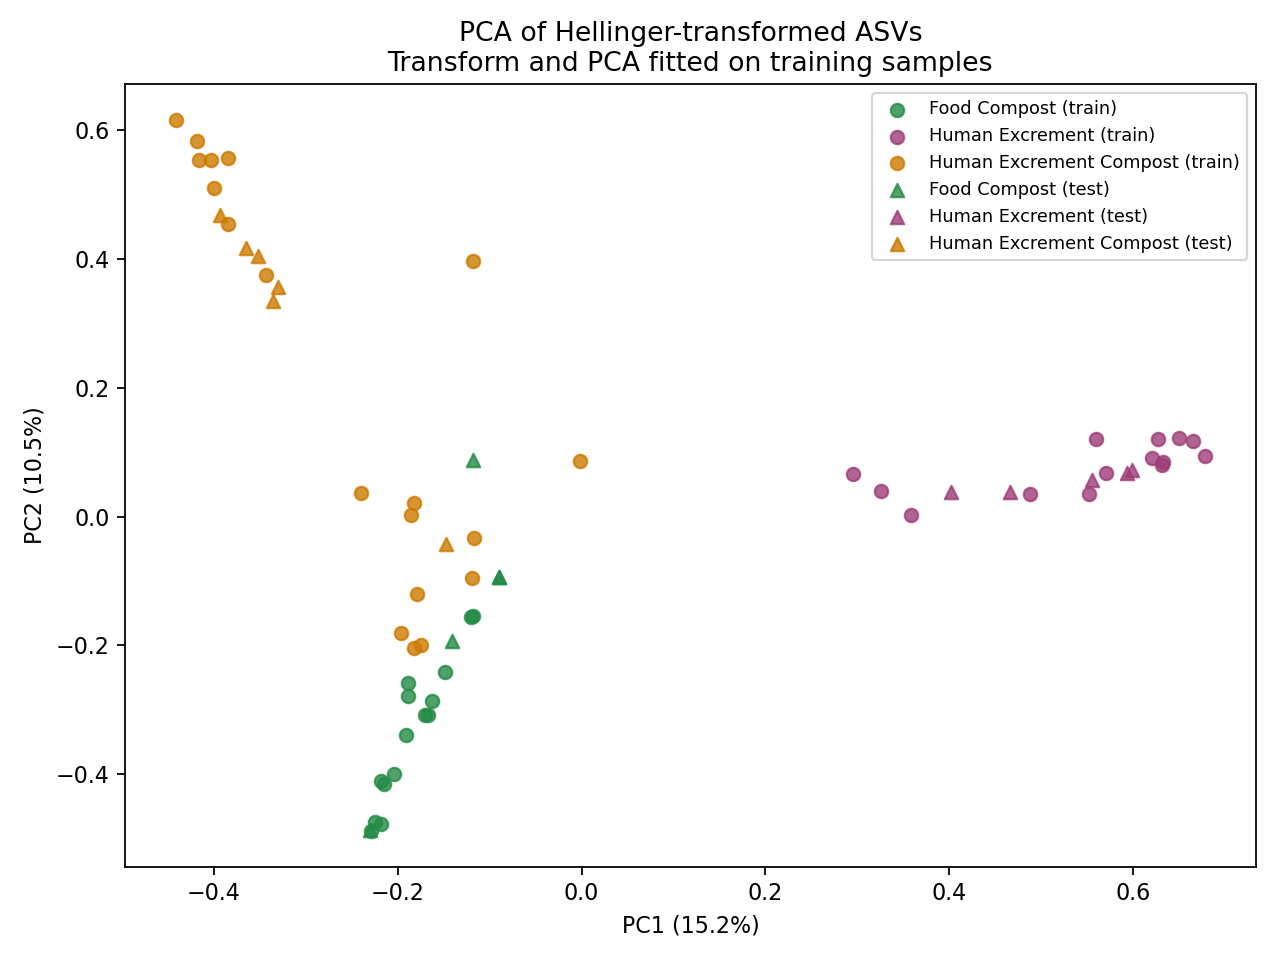

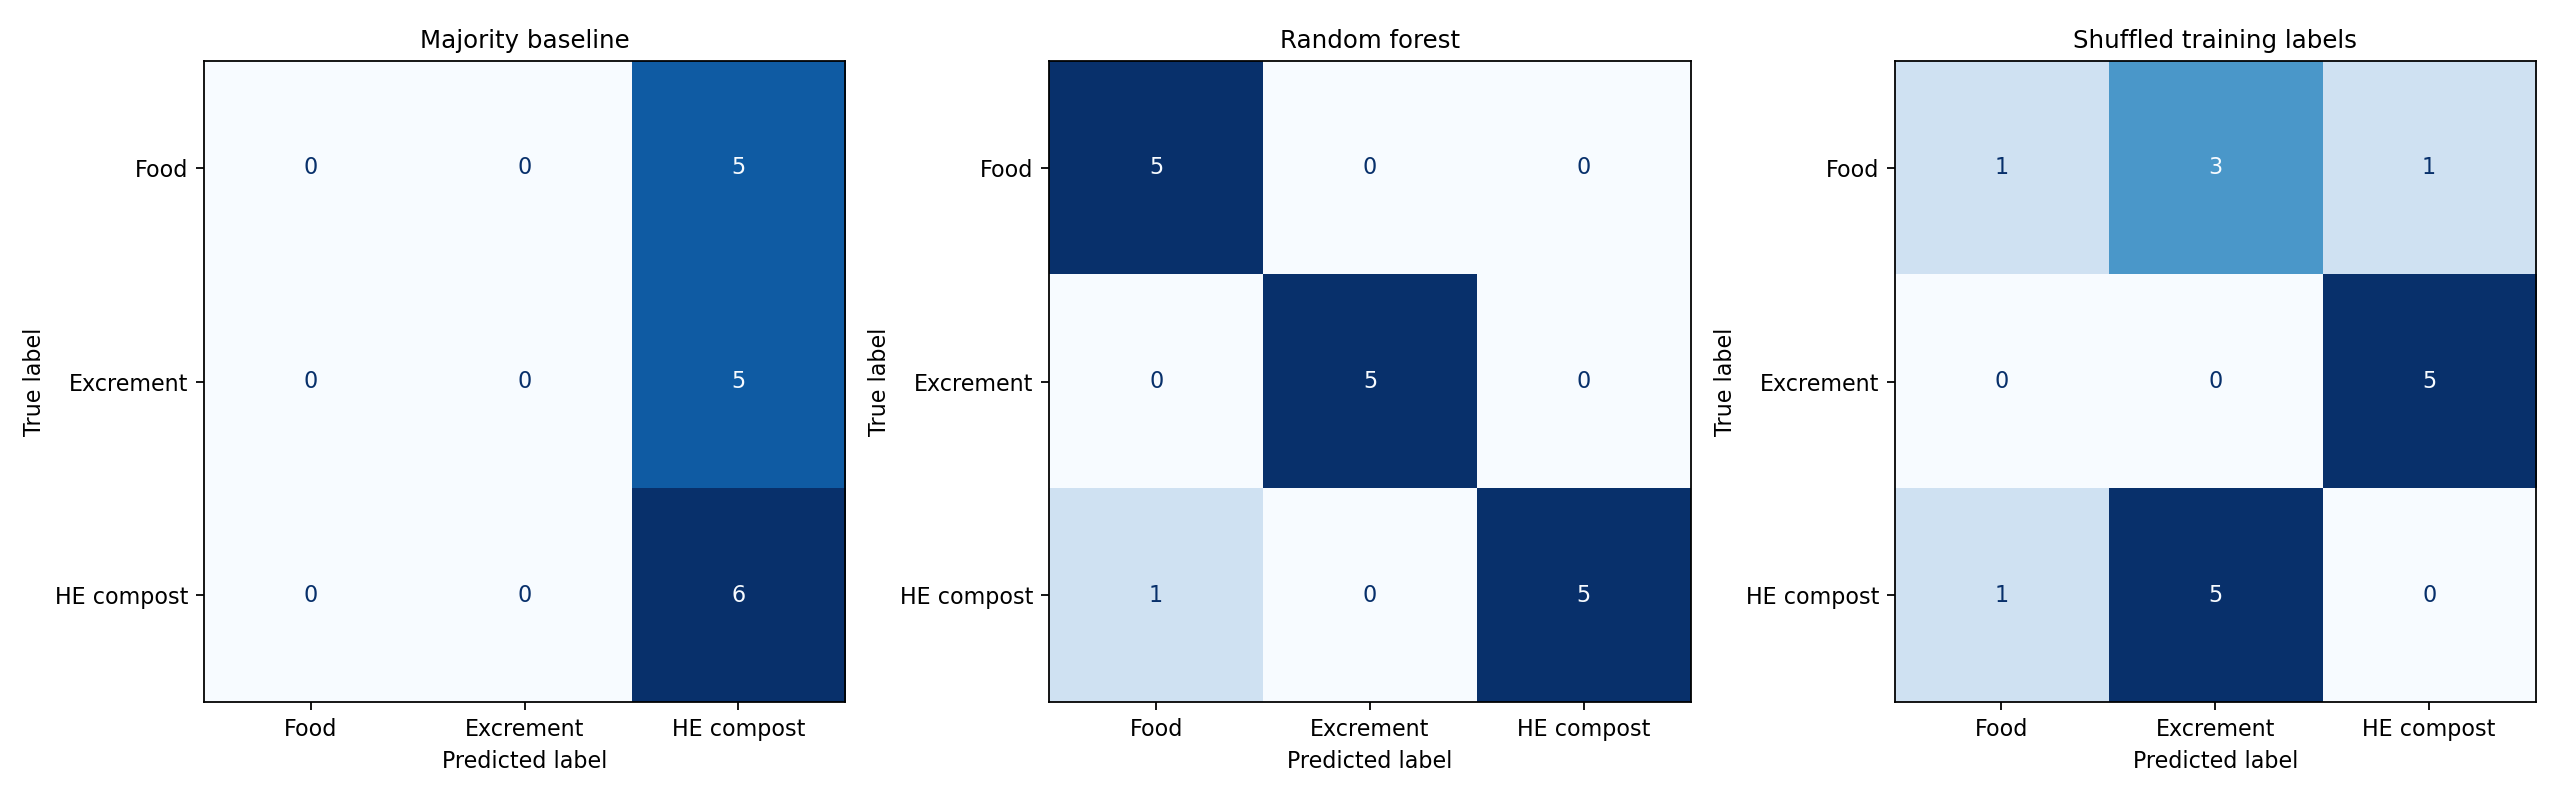

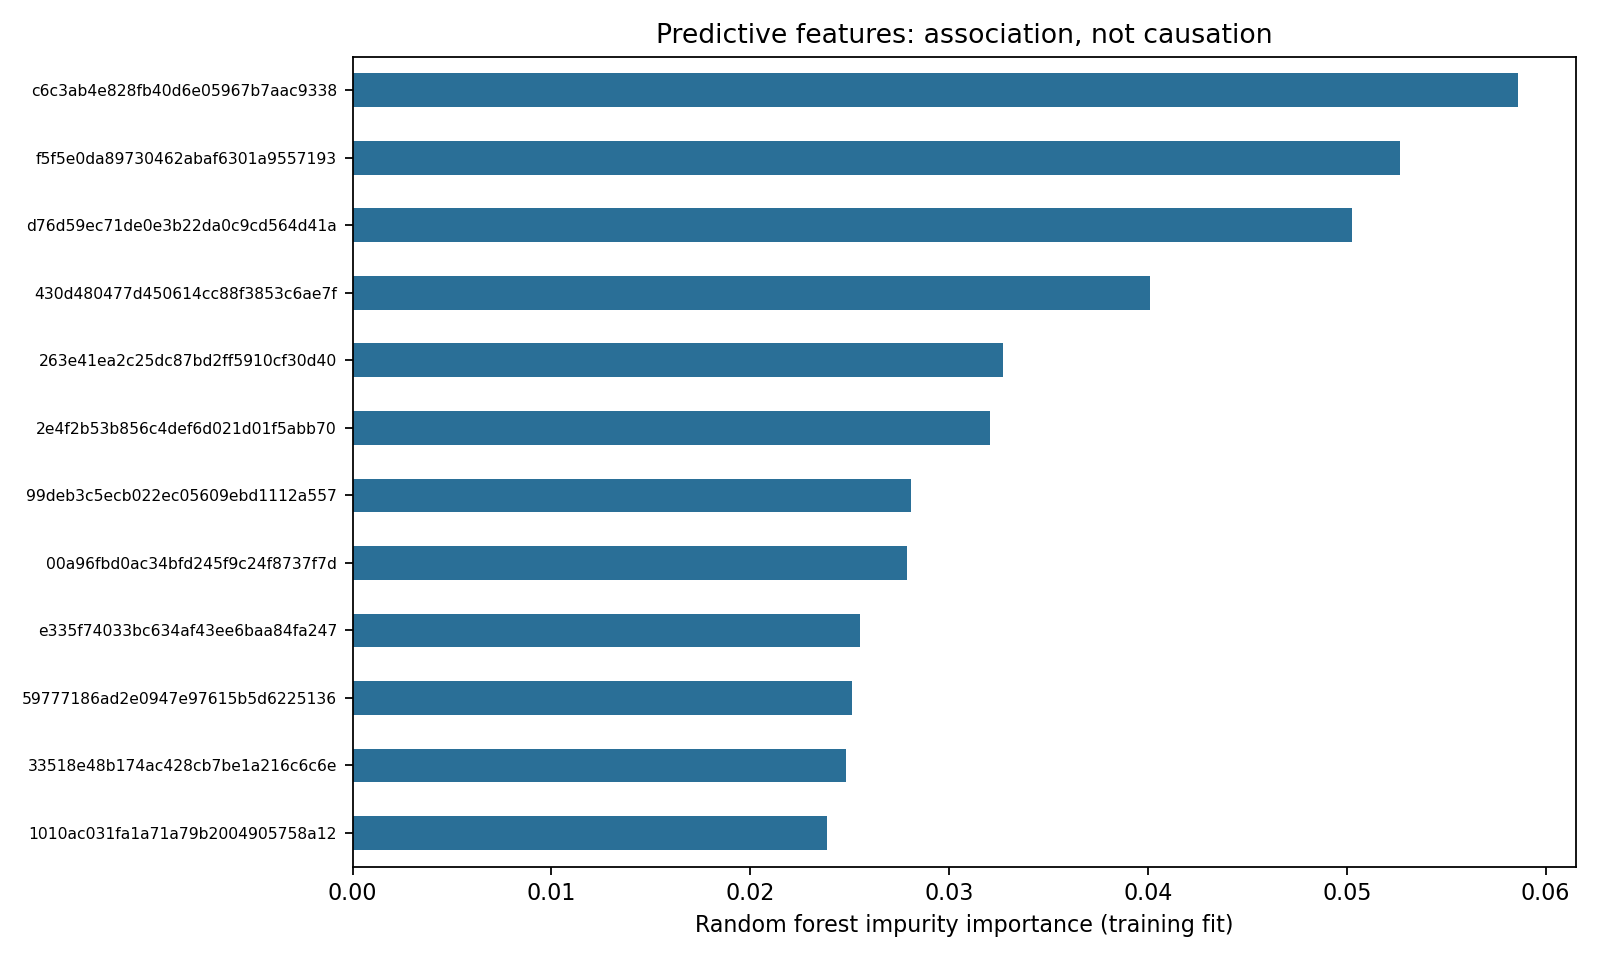

Gut-to-soil sample classification
Samples: 64; ASVs: 1069; train: 48; test: 16
Class counts:
SampleType
Human Excrement Compost    25
Food Compost               20
Human Excrement            19

Majority baseline
                         precision    recall  f1-score   support

           Food Compost       0.00      0.00      0.00         5
        Human Excrement       0.00      0.00      0.00         5
Human Excrement Compost       0.38      1.00      0.55         6

               accuracy                           0.38        16
              macro avg       0.12      0.33      0.18        16
           weighted avg       0.14      0.38      0.20        16


Random forest
                         precision    recall  f1-score   support

           Food Compost       0.83      1.00      0.91         5
        Human Excrement       1.00      1.00      1.00         5
Human Excrement Compost       1.00      0.83      0.91         6

               accuracy                           0.

In [46]:
from IPython.display import display, Image
for name in ['pca.png','confusion-matrices.png','feature-importance.png']:
    path=WORK/'ml'/name
    if path.exists(): display(Image(filename=str(path)))
print((WORK/'ml'/'evaluation.txt').read_text())


### Student interpretation

1. Contrast sequence-level taxonomy classification with sample-level environment classification: observations, features, labels, and reference information.
2. Compare the random forest with the baseline and shuffled-label control. Which errors dominate? Why can accuracy alone be misleading?
3. Does the random split put samples from the same bucket on both sides? How does that affect the claim being evaluated?
4. Compare PCA and PCoA. Does visible separation guarantee accurate prediction on a new biological replicate?
5. Identify one influential ASV. Does importance establish causation? Compare predictive importance with differential abundance, explaining why they need not agree.
6. State two limitations: the small, shallow dataset; compositional features; study dependence; incomplete reference taxonomy; or another evidence-based concern.

**Optional experiment:** change one model setting only after stating a prediction. For genuine model selection, use cross-validation within the training set and reserve a new final test set. Repeatedly optimizing against the displayed test score contaminates that evaluation.

**Your responses:**

1. Sequence-level taxonomy classification treats one DNA sequence as an observation, represents it by k-mers, and predicts its reference taxonomic lineage. Sample-level classification treats one microbial community as an observation, uses its ASV abundance profile, and predicts SampleType from this study's labeled samples.
2. On the held-out split, the random forest has accuracy 93.8% and balanced accuracy 94.4%. The majority baseline has accuracy 37.5% and balanced accuracy 33.3%; the shuffled-label control has accuracy 6.2% and balanced accuracy 6.7%. The forest makes one error: one Human Excrement Compost sample is classified as Food Compost. It correctly classifies all five Human Excrement and all five Food Compost test samples, supporting the prediction that the two compost categories are hardest to separate. Per-class recall and balanced accuracy matter because overall accuracy can conceal poor recognition of a smaller class. One shuffled-label run is a control, not a formal permutation test.
3. Groups overlapping random training/test partitions: ['bucket:10', 'bucket:12', 'bucket:13', 'bucket:5', 'bucket:7'] Shared buckets put dependent observations on both sides, so the random split can reward recognition of a familiar biological source. Separate 3-fold bucket-grouped CV balanced accuracies: [0.75  0.685 0.667] Their mean balanced accuracy is 70.1%. These grouped folds differ from the single holdout and are not a paired comparison. Missing bucket IDs do not establish independence, and donor or collection-source grouping may be needed.
4. PCA works on the Hellinger-transformed feature matrix, with transformation and PCA fitted on training data before test projection. PCoA works on pairwise community dissimilarities. Either plot can show separation without guaranteeing transfer to new buckets.
5. The most influential ASV in this fitted forest is c6c3ab4e828fb40d6e05967b7aac9338, with training-derived impurity importance 0.0586. This is the Blautia_A-associated ASV that also has a positive Human Excrement versus compost coefficient in ANCOM-BC2, with q = 0.0382. The two analyses therefore agree on its gut association here. Importance shows predictive use by this model, not causation. Correlated features and interactions can make a useful predictor differ from a marginal differential-abundance result, and a statistically different feature may add little information beyond other predictors.
6. This small, shallow subset can miss rare organisms and produce unstable scores. Two held-out samples have no counts remaining after the training-derived feature filter, which further limits interpretation of their predictions. The features are compositional, the study contains dependent samples, and reference taxonomy is incomplete. ASV inference also used the full sequencing run, so this is a within-study teaching evaluation rather than strict external validation. An independent external dataset is needed before claiming general performance.


## Verified results from this run

These summaries are calculated from the QIIME artifacts generated above. Read-quality, composition, and ordination images below are static views of the computed data. The QZV files retain the full interactive results and provenance.

| Quantity | Computed result |
| --- | ---: |
| ASVs before the prevalence filter | 1,069 |
| Retained reads before the prevalence filter | 39,949 |
| ASVs after the prevalence filter | 335 |
| Nonempty samples after the prevalence filter | 99 |
| Samples retained at diversity depth 96 | 74 |
| ASVs excluded by the prevalence filter | 734 |

In the lecture's terms, richness counts observed features and Shannon diversity also reflects their relative balance. Beta diversity compares communities. Ordination summarizes those differences, while supervised classification evaluates whether community profiles predict sample labels.


In [47]:
#@title Generate numerical summaries from the computed artifacts
summary_script = ROOT / 'verified_summary.py'
summary_script.write_text('"""Summarize computed QIIME artifacts without substituting reference results."""\nfrom pathlib import Path\nfrom io import StringIO\nimport zipfile, tempfile, json, sys, itertools\nimport numpy as np\nimport pandas as pd\nfrom biom import load_table\nimport matplotlib\nmatplotlib.use(\'Agg\')\nimport matplotlib.pyplot as plt\nfrom skbio import DistanceMatrix\nfrom skbio.stats.ordination import pcoa\n\nwork=Path(sys.argv[1])\nout=work/\'verified-summary\'\nout.mkdir(exist_ok=True)\nfocal=[\'Human Excrement\',\'Human Excrement Compost\',\'Food Compost\']\ncolors=[\'#9d4269\',\'#d28a19\',\'#25835c\']\nreport={}\n\ndef members(path):\n    with zipfile.ZipFile(path) as z:\n        return {n.split(\'/data/\',1)[1]:z.read(n) for n in z.namelist()\n                if \'/data/\' in n and not n.endswith(\'/\') and \'/provenance/\' not in n}\n\ndef count_table(name):\n    data=members(work/name)\n    key=next(k for k in data if k.endswith(\'.biom\'))\n    with tempfile.TemporaryDirectory() as temp:\n        p=Path(temp)/\'table.biom\'\n        p.write_bytes(data[key])\n        return load_table(str(p)).to_dataframe(dense=True)\n\ndef text_table(name, desired=None):\n    data=members(work/name)\n    key=desired or next(k for k in data if k.endswith(\'.tsv\'))\n    return pd.read_csv(StringIO(data[key].decode()),sep=\'\\t\',index_col=0)\n\nquality=members(work/\'demux.qzv\')\nfig,axes=plt.subplots(1,2,figsize=(11,4),sharey=True)\nquality_summary={}\nfor ax,direction,color in zip(axes,[\'forward\',\'reverse\'],[\'#2469a1\',\'#b65e26\']):\n    frame=pd.read_csv(StringIO(quality[direction+\'-seven-number-summaries.tsv\'].decode()),sep=\'\\t\',index_col=0)\n    positions=frame.columns.astype(int).to_numpy()\n    median=frame.loc[\'50%\'].to_numpy(dtype=float)\n    low=frame.loc[\'25%\'].to_numpy(dtype=float)\n    high=frame.loc[\'75%\'].to_numpy(dtype=float)\n    ax.plot(positions,median,color=color,label=\'Median\')\n    ax.fill_between(positions,low,high,color=color,alpha=.2,label=\'Interquartile range\')\n    ax.axvline(250,color=\'#333333\',linestyle=\'--\',linewidth=1,label=\'Truncation at 250\')\n    ax.set(title=direction.capitalize()+\' reads\',xlabel=\'Base position\',ylabel=\'Phred quality\')\n    ax.set_ylim(0,45)\n    ax.legend(fontsize=8,loc=\'lower left\')\n    quality_summary[direction]={str(k):float(frame.loc[\'50%\',str(k)]) for k in [1,125,250,251]}\nfig.suptitle(\'Computed read quality from the demultiplexed input\')\nfig.tight_layout()\nfig.savefig(out/\'read-quality.png\',dpi=160)\nplt.close(fig)\nreport[\'quality_medians\']=quality_summary\n\nraw=count_table(\'asv-table.qza\')\nfiltered=count_table(\'asv-table-ms2.qza\')\nmeta=pd.read_csv(work/\'sample-metadata.tsv\',sep=\'\\t\',index_col=0,dtype=str)\nmeta=meta.loc[~meta.index.astype(str).str.startswith(\'#\')]\nmetadata=meta.reindex(filtered.columns)\ntax=text_table(\'taxonomy.qza\')\nstats=text_table(\'denoising-stats.qza\')\nstats=stats.loc[~stats.index.astype(str).str.startswith(\'#\')].apply(pd.to_numeric)\ntop=raw.sum(axis=1).idxmax()\nseqdata=members(work/\'asv-seqs.qza\')\nfasta=next(v.decode() for k,v in seqdata.items() if k.endswith((\'.fasta\',\'.fa\',\'.fna\')))\nsequences={}\nfor block in fasta.split(\'>\')[1:]:\n    lines=block.strip().splitlines()\n    sequences[lines[0].split()[0]]=\'\'.join(lines[1:])\nsequence=sequences[top]\nreport[\'counts\']={\n    \'unfiltered_samples\':int(raw.shape[1]),\'unfiltered_ASVs\':int(raw.shape[0]),\n    \'unfiltered_nonempty_samples\':int((raw.sum(axis=0)>0).sum()),\n    \'unfiltered_empty_sample_ids\':list(raw.columns[raw.sum(axis=0)==0].astype(str)),\n    \'unfiltered_total_reads\':int(raw.to_numpy().sum()),\n    \'filtered_samples\':int(filtered.shape[1]),\'filtered_ASVs\':int(filtered.shape[0]),\n    \'removed_ASVs\':int(raw.shape[0]-filtered.shape[0]),\n    \'filtered_total_reads\':int(filtered.to_numpy().sum()),\n    \'removed_reads\':int(raw.to_numpy().sum()-filtered.to_numpy().sum()),\n    \'sample_ids_removed_by_filter\':list(raw.columns.difference(filtered.columns).astype(str)),\n    \'top_ASV\':str(top),\'top_ASV_reads\':int(raw.loc[top].sum()),\n    \'top_ASV_samples\':int((raw.loc[top]>0).sum()),\n    \'top_ASV_length\':len(sequence),\'top_ASV_GC_percent\':round(100*(sequence.count(\'G\')+sequence.count(\'C\'))/len(sequence),2),\n    \'top_ASV_sequence_start\':sequence[:40],\n    \'top_ASV_taxonomy\':tax.loc[top].to_dict(),\n}\nsample=\'21f2e6d0\' if \'21f2e6d0\' in stats.index else str(stats.index[0])\nreport[\'chosen_denoising_sample\']={\'sample_id\':sample,**stats.loc[sample].to_dict()}\ndepths=filtered.sum(axis=0)\nreport[\'retention\']={}\nfor depth in [96,180,260]:\n    report[\'retention\'][str(depth)]={\n        \'samples\':int((depths>=depth).sum()),\'fraction\':float((depths>=depth).mean()),\n        \'by_type\':metadata.loc[depths>=depth,\'SampleType\'].value_counts().to_dict()}\n\nrelative=filtered.div(filtered.sum(axis=0),axis=1)\ntaxon=tax[\'Taxon\'].reindex(relative.index).fillna(\'Unassigned\')\nmeans={}\nfig,axes=plt.subplots(1,2,figsize=(13,5))\nfor ax,level,label in zip(axes,[2,6],[\'Phylum\',\'Genus\']):\n    def at_level(lineage):\n        parts=[s.strip() for s in lineage.split(\';\')]\n        return parts[level-1] if len(parts)>=level else parts[-1]+\' (unresolved)\'\n    grouped=relative.groupby(taxon.map(at_level)).sum()\n    category_means=pd.DataFrame({category:grouped.loc[:,metadata[\'SampleType\']==category].mean(axis=1)\n                               for category in focal})\n    means[label]={category:{str(k):float(v) for k,v in category_means[category].nlargest(5).items()}\n                  for category in focal}\n    selected=category_means.mean(axis=1).nlargest(6).index\n    plot=category_means.loc[selected].T.copy()\n    plot[\'Other\']=1-plot.sum(axis=1)\n    plot.plot.bar(stacked=True,ax=ax,cmap=\'tab20\',width=.7)\n    ax.set(title=f\'{label}: mean per-sample relative abundance\',ylabel=\'Read fraction\',xlabel=\'\')\n    ax.set_xticklabels([\'Human\\nexcrement\',\'Excrement\\ncompost\',\'Food\\ncompost\'],rotation=0)\n    ax.legend(fontsize=7,bbox_to_anchor=(1.01,1),loc=\'upper left\',frameon=False)\n    ax.set_ylim(0,1)\nfig.suptitle(\'Computed community profiles after the minimum-two-samples filter\',fontsize=12)\nfig.tight_layout()\nfig.savefig(out/\'composition.png\',dpi=160,bbox_inches=\'tight\')\nplt.close(fig)\nreport[\'mean_relative_abundance\']=means\nreport[\'top_ASV_relative_abundance\']={cat:float(relative.loc[top,metadata[\'SampleType\']==cat].mean())\n                                     for cat in focal}\n\ndistance_dir=work/\'boots-kmer-diversity\'/\'distance_matrices\'\ndistance_results={}\nbray=None\nfor artifact in sorted(distance_dir.rglob(\'*.qza\')):\n    data=members(artifact)\n    key=next((k for k in data if \'distance\' in k and k.endswith(\'.tsv\')),None)\n    if key is None:\n        continue\n    matrix=pd.read_csv(StringIO(data[key].decode()),sep=\'\\t\',index_col=0)\n    group=meta.reindex(matrix.index)[\'SampleType\']\n    comparison={}\n    for a,b in itertools.combinations_with_replacement(focal,2):\n        ids_a=list(group[group==a].index);ids_b=list(group[group==b].index)\n        values=matrix.loc[ids_a,ids_b].to_numpy()\n        values=values[np.triu_indices_from(values,k=1)] if a==b else values.ravel()\n        comparison[a+\' vs \'+b]={\'mean_distance\':float(np.mean(values)),\'pairs\':int(len(values))}\n    distance_results[artifact.stem]=comparison\n    if \'bray\' in artifact.stem.lower():\n        bray=matrix\nif bray is not None:\n    ordination=pcoa(DistanceMatrix(bray.to_numpy(),ids=bray.index.astype(str)),\n                    dimensions=2,warn_neg_eigval=False)\n    coords=ordination.samples\n    group=meta.reindex(coords.index)[\'SampleType\']\n    fig,ax=plt.subplots(figsize=(8,6))\n    for cat,color in zip(focal,colors):\n        selected=group==cat\n        ax.scatter(coords.loc[selected,\'PC1\'],coords.loc[selected,\'PC2\'],color=color,\n                   s=45,alpha=.85,label=f\'{cat} (n={selected.sum()})\',edgecolor=\'white\',linewidth=.4)\n    ax.set(xlabel=f\'PCoA 1 ({ordination.proportion_explained.iloc[0]:.1%})\',\n           ylabel=f\'PCoA 2 ({ordination.proportion_explained.iloc[1]:.1%})\',\n           title=\'Computed k-mer Bray-Curtis ordination\\nFocal environments from the tutorial subset\')\n    ax.legend(fontsize=8,frameon=False)\n    fig.tight_layout()\n    fig.savefig(out/\'ordination.png\',dpi=160)\n    plt.close(fig)\nreport[\'distance_comparisons\']=distance_results\n\ndef ancom_slices(name):\n    data=members(work/name)\n    slices={}\n    for key,value in data.items():\n        if key.endswith(\'.jsonl\'):\n            try:\n                lines=value.decode().splitlines()\n                header=json.loads(lines[0])\n                if \'doctype\' in header:\n                    lines=lines[1:]\n                frame=pd.read_json(StringIO(\'\\n\'.join(lines)),lines=True)\n                index_columns=header.get(\'index\',[]) if \'doctype\' in header else []\n                if index_columns and all(k in frame.columns for k in index_columns):\n                    frame=frame.set_index(index_columns,drop=False)\n                elif \'id\' in frame.columns:\n                    frame=frame.set_index(\'id\',drop=False)\n                elif \'taxon\' in frame.columns:\n                    frame=frame.set_index(\'taxon\',drop=False)\n                slices[Path(key).stem]=frame\n            except ValueError:\n                pass\n    return slices\n\nfor name,label in [(\'ancombc2-results.qza\',\'ASV\'),(\'genus-ancombc2-results.qza\',\'Genus\')]:\n    slices=ancom_slices(name)\n    for key,df in slices.items():\n        df.to_csv(out/(label.lower()+\'-\'+key+\'.tsv\'),sep=\'\\t\',index=False)\n    report[label+\'_ANCOM_slices\']={k:{\'columns\':list(v.columns),\'rows\':len(v)} for k,v in slices.items()}\n    example=top if label==\'ASV\' else next((str(k) for k in slices.get(\'lfc\',pd.DataFrame()).index\n                                         if \'g__Blautia_A\' in str(k)),None)\n    if example is not None and \'lfc\' in slices and example in slices[\'lfc\'].index:\n        report[label+\'_ANCOM_example\']={\'feature\':str(example),\n            **{key:df.loc[example].to_dict() for key,df in slices.items() if example in df.index}}\n\ndef convert(value):\n    if isinstance(value,np.generic):return value.item()\n    raise TypeError(type(value).__name__)\n(out/\'summary.json\').write_text(json.dumps(report,indent=2,default=convert)+\'\\n\')\nprint(json.dumps(report,indent=2,default=convert))\nprint(\'\\nAll summaries above were calculated from this notebook run.\')\n')
run([MM, 'run', '-p', PREFIX, 'python', summary_script, str(WORK)], 'verified-summary')


$ /content/gut_to_soil_student/bin/micromamba run -p /content/gut_to_soil_student/qiime-2026.10 python /content/gut_to_soil_student/verified_summary.py /content/gut_to_soil_student/analysis
{
  "quality_medians": {
    "forward": {
      "1": 33.0,
      "125": 39.0,
      "250": 37.0,
      "251": 37.0
    },
    "reverse": {
      "1": 33.0,
      "125": 39.0,
      "250": 37.0,
      "251": 14.0
    }
  },
  "counts": {
    "unfiltered_samples": 104,
    "unfiltered_ASVs": 1069,
    "unfiltered_nonempty_samples": 103,
    "unfiltered_empty_sample_ids": [
      "48dff3fa"
    ],
    "unfiltered_total_reads": 39949,
    "filtered_samples": 99,
    "filtered_ASVs": 335,
    "removed_ASVs": 734,
    "filtered_total_reads": 29978,
    "removed_reads": 9971,
    "sample_ids_removed_by_filter": [
      "48dff3fa",
      "5afa94c0",
      "a4415b92",
      "adf70ace",
      "bcc246ab"
    ],
    "top_ASV": "c6c3ab4e828fb40d6e05967b7aac9338",
    "top_ASV_reads": 1334,
    "top_ASV_samples":

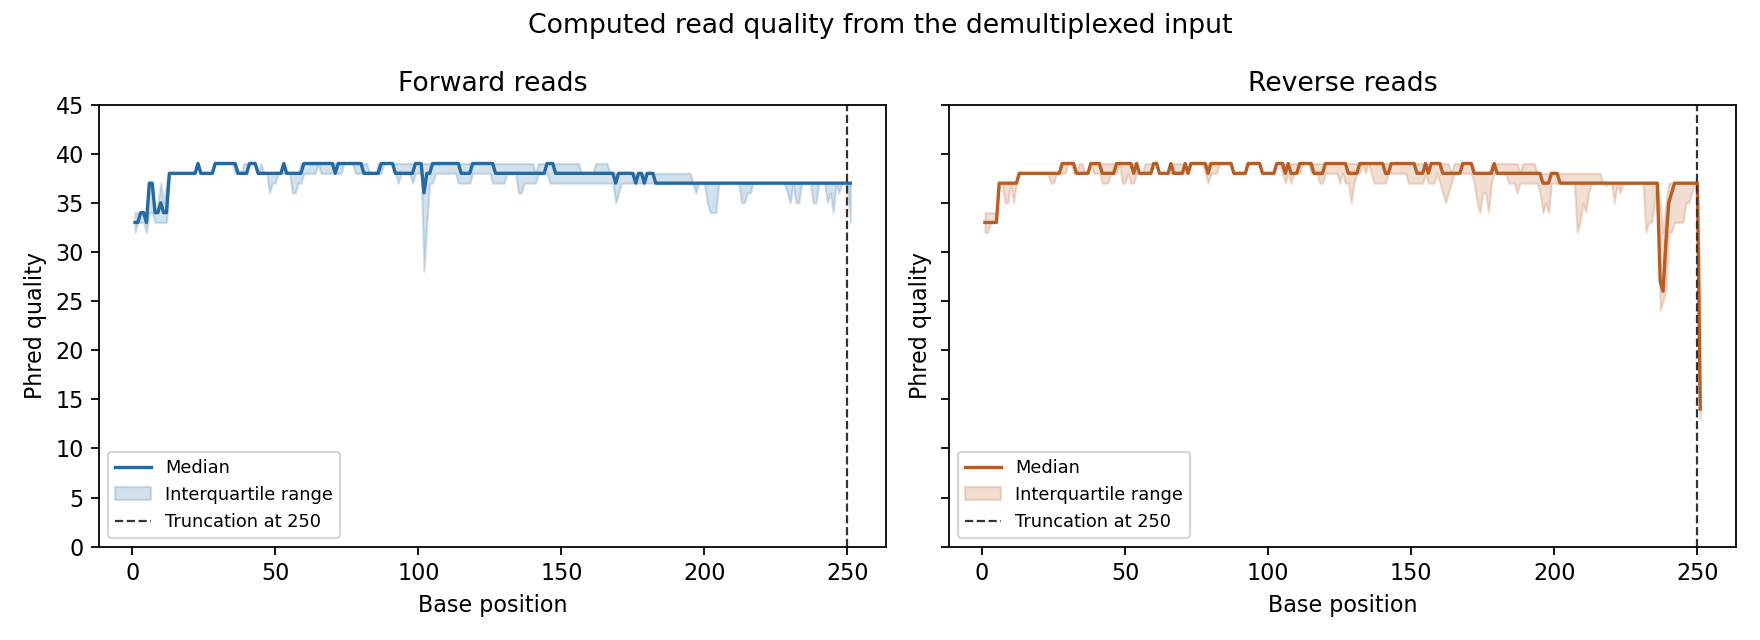

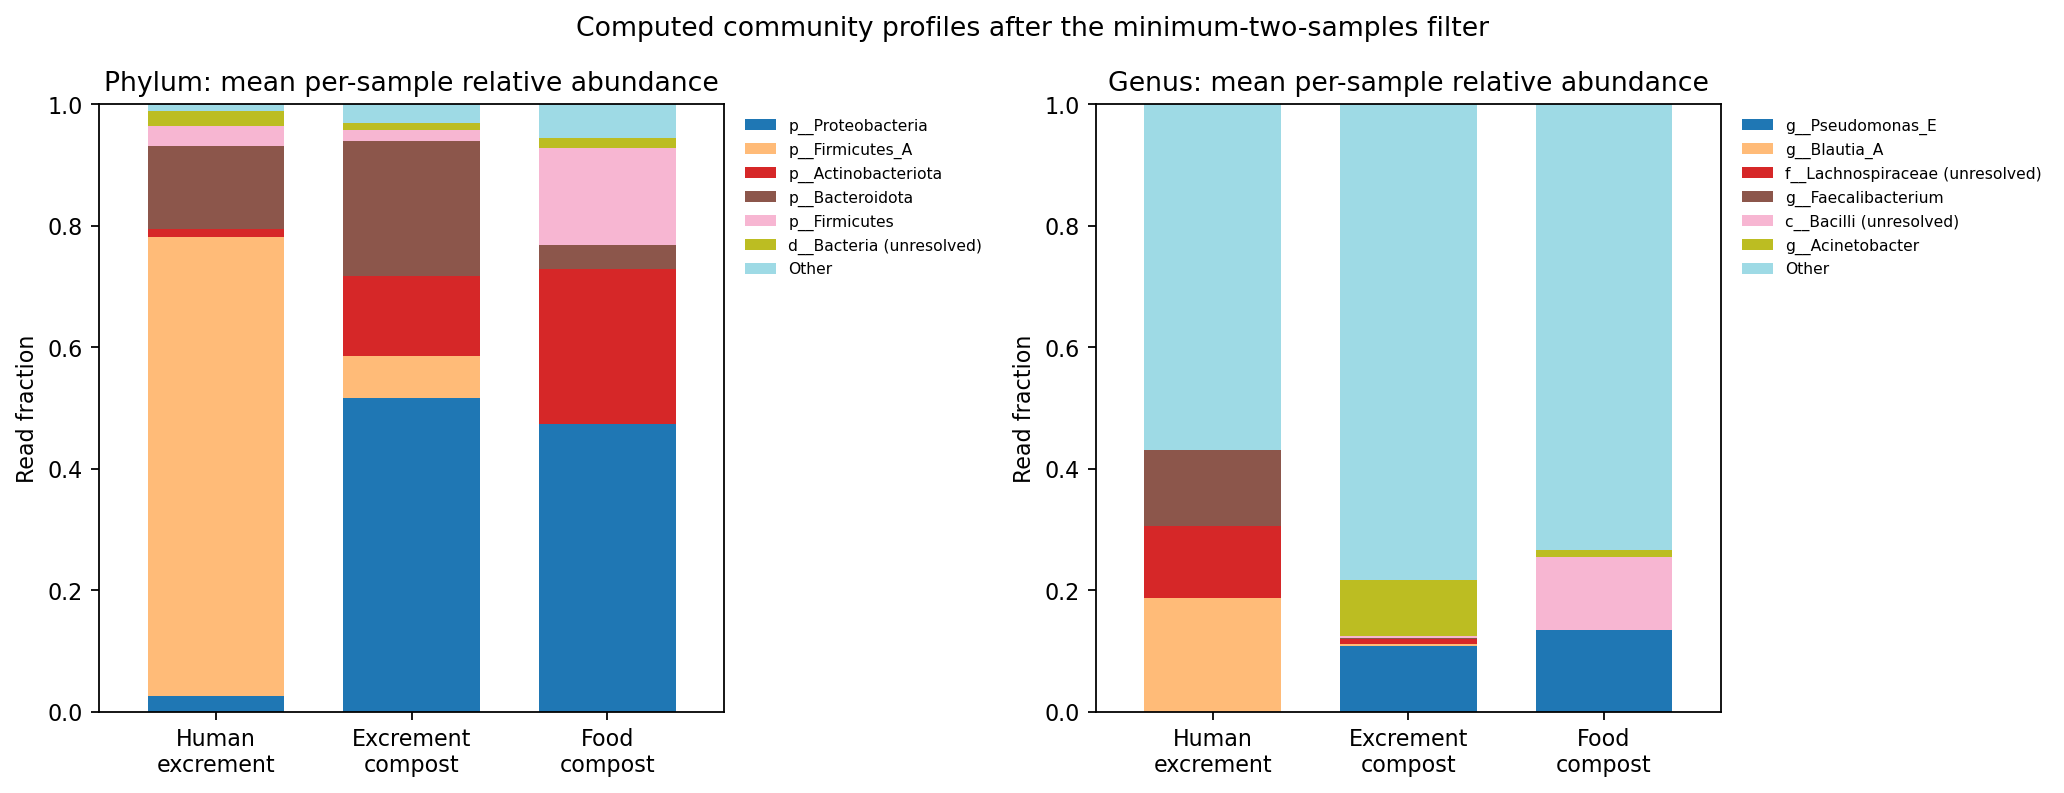

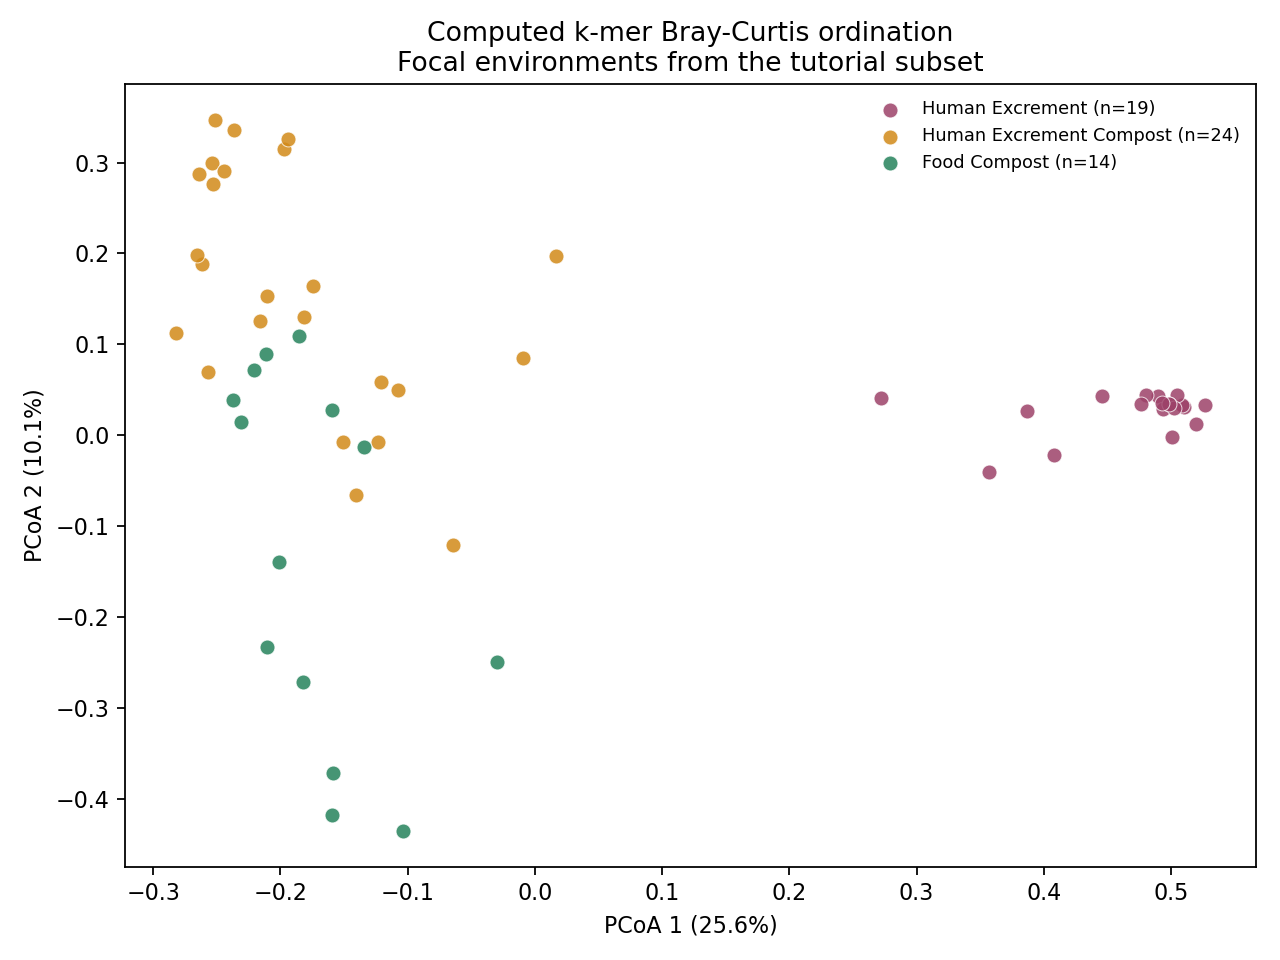

In [48]:
from IPython.display import display, Image
for name in ['read-quality.png', 'composition.png', 'ordination.png']:
    image_path = WORK / 'verified-summary' / name
    if image_path.exists():
        display(Image(filename=str(image_path)))


## Export results before leaving Colab

This archive includes analysis artifacts, plots, scripts, logs, file checksums, and environment information. It excludes the installed environment, the large input read artifact, and reference/trained-classifier artifacts, which can be regenerated or downloaded again. Each downstream QIIME artifact retains its own provenance.


In [49]:
archive=ROOT/'gut_to_soil_results.zip'
excluded={'demux.qza','reference-sequences.qza','reference-taxonomy.qza',
          'suboptimal-16S-rRNA-classifier.qza','teaching-classifier.qza'}
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for directory in [WORK,LOGS,ROOT/'reference-recovery']:
        if directory.exists():
            for p in directory.rglob('*'):
                if p.is_file() and p.name not in excluded:
                    z.write(p,p.relative_to(ROOT))
    for pattern in ['*.json','*.yml','*.py','*.bash']:
        for p in ROOT.glob(pattern): z.write(p,p.name)
print('Archive:',archive,round(archive.stat().st_size/1e6,1),'MB')
try:
    from google.colab import files
    files.download(str(archive))
except ImportError:
    from IPython.display import display, FileLink
    display(FileLink(str(archive)))


Archive: /content/gut_to_soil_student/gut_to_soil_results.zip 49.8 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Recovery: published visualizations without a working QIIME installation

Run section 1, then this cell if installation or a later computation prevents class from continuing. It downloads **published reference visualizations into a separate folder**, never into the computed analysis. These are not your computed results. Open them in QIIME 2 View. This recovery route supports interpretation, not a claim that the workflow ran successfully. It still requires working internet downloads.


In [50]:
RECOVERY = False  # change to True only when intentionally using published results
if RECOVERY:
    recovery=ROOT/'reference-recovery'; recovery.mkdir(exist_ok=True)
    names=['demux.qzv','denoising-stats.qzv','asv-table-ms2.qzv','taxa-bar-plots.qzv',
           'alpha-rarefaction.qzv','boots-kmer-diversity/scatter_plot.qzv',
           'ancombc2-barplot.qzv','genus-ancombc2-barplot.qzv']
    failures=[]
    for name in names:
        try: download(BASE+name,recovery/name)
        except Exception as e: failures.append((name,str(e)))
    record('checkpoints.json',dict(step='Reference visualizations only',files=names,failures=failures))
    recovered=ROOT/'published_reference_visualizations.zip'
    with zipfile.ZipFile(recovered,'w') as z:
        for p in recovery.rglob('*.qzv'): z.write(p,p.relative_to(recovery))
    print('PUBLISHED REFERENCE RESULTS — not computed in this runtime. Failures:',failures)
    try:
        from google.colab import files
        files.download(str(recovered))
    except ImportError:
        from IPython.display import display, FileLink
        display(FileLink(str(recovered)))
else:
    print('Recovery disabled. Your computed results are unchanged.')


Recovery disabled. Your computed results are unchanged.


## Final reflection and submission checklist

- [x] All 24 tutorial commands are completed and their outputs are saved.
- [x] Read quality, taxonomy, diversity, and differential-abundance results were computed.
- [x] All notebook interpretation prompts and three exit questions are answered.
- [x] Published recovery visualizations were not substituted for computed results.
- [x] The completed notebook and results ZIP are prepared.
- [ ] Save the notebook to GitHub and submit the repository notebook URL.

**Synthesis (one paragraph):** What evidence supports a difference among microbial communities in the three focal environments? Distinguish descriptive patterns, statistical association, and prediction. State one limitation of this dataset or analysis.

The community profiles support differences among the focal environments: taxonomic composition changes between human excrement and compost, while community-distance ordination places the samples in groups associated with SampleType. These plots describe patterns. ANCOM-BC2 tests model-based abundance associations, and the sample-level classifier evaluates whether those patterns help predict labels on held-out observations. Neither association nor prediction establishes causation or compost safety. The shallow single-run subset and repeated sampling from buckets limit precision and independence, so conclusions about new buckets need grouped evaluation and additional independent data.

### If something fails
A placeholder message means you have not pasted the command yet. An unknown option usually indicates the wrong tutorial release or an incomplete paste. Check that you used the Command Line tab, included all output flags, and retained filenames. A failed command prints its log location; preserve the error for your instructor. Do not run downstream commands until their inputs exist. Use the separately labeled recovery plots only if directed.


### Sources
[Gut-to-soil tutorial, QIIME 2 2026.10](https://gut-to-soil-tutorial.readthedocs.io/en/2026.10/), by Caporaso and colleagues, based on the study by Meilander and colleagues. The linked tutorial contains the full explanations and citations. This completed course notebook supplies all requested commands and responses and retains the Colab workflow. The optional sample-classification extension is course material, separate from the official tutorial.


## Exit Questions

### 1. What do the microbial communities suggest?

Do human-excrement compost communities resemble human excrement, food compost, or fall between them? Support your interpretation with two specific results or visualizations from your notebook. Describe any variation or exceptions that affect your conclusion.

**Your response:** Human-excrement compost is more food-compost-like overall in the computed ordination, while retaining a distinct and variable community. First, mean k-mer Bray-Curtis dissimilarity is 0.809 between excrement compost and food compost, compared with 0.877 between excrement compost and human excrement. The ordination separates human excrement from both compost groups and shows partial overlap between compost categories. Second, the Blautia_A-associated ASV is less abundant in compost: Human Excrement versus compost has log fold change +1.839 with adjusted q = 0.0382. Together these support a shift away from the original gut community. Some compost samples overlap the food-compost group, while others remain separated along the second coordinate. This shallow, mostly cross-sectional subset does not establish the same trajectory for every bucket or prove that excrement compost becomes identical to food compost.

### 2. Could a classifier detect a fecal microbial signature?

Suppose you trained a classifier to distinguish human excrement from food compost, then applied it to human-excrement compost samples. What would its predictions tell you? Why would an “excrement-like” prediction not establish contamination or show that the compost is unsafe?

**Your response:** The predictions would describe which of the two training environments each compost sample most resembles in the measured ASV profile. An excrement-like prediction could indicate a remaining gut-associated community signal, but it could also reflect ordinary taxa shared among environments, uneven reference coverage, or study-specific patterns. A binary classifier must choose between its two labels even when a compost community belongs between or outside them. Short 16S sequences do not directly measure pathogen viability, virulence genes, infectious dose, or chemical hazards. As the lecture explains, 16S profiling identifies community composition with limited taxonomic resolution. Therefore, a similarity label alone cannot establish contamination or determine safety.

### 3. How should we evaluate predictions?

Several samples came from the same composting bucket. Why could randomly dividing samples into training and test sets overestimate performance on new buckets? Describe a better way to split the data and explain what that evaluation would test.

**Your response:** Samples from one bucket share biological material, environmental conditions, and often a donor, so a random sample split can place closely related observations in both partitions. The model may learn a familiar bucket signature and appear more accurate than it would be on a new independent bucket. I would use a grouped train/test split or grouped cross-validation that keeps every sample from a bucket in one partition, balancing environments across folds where feasible. Feature filtering and model tuning must use only each training fold. When donors contribute multiple buckets, grouping by donor can provide a stronger test. This evaluation asks whether the classifier transfers to unseen biological sources, while a separate external cohort would test broader generalization.
